# Environment
1. The grid world is 5 * 5, and all agents position and B position is random initialized. 
2. If B born on any one position of agent, B position will be random again until B not born on any one agent position.
3. Once all positions are successful initialized, a inspection of whether different types agents exchange their secrets will be applied.

# DQN structure 
1. DQN including input layer(state space 7), 3 hidden layers(150, 100, 50) and output layer(4, 4 actions)
2. Input layer, 7 neurons, including agent type(type 1 or type 2), agent index(first agent id 0 or second agent id 1), agent current position(x, y), B position (x, y) and whether agent carry full secret(0 or 1). Flatten like this [agent type, agent id, agent x position, agent y position, B x position, B y position, whether carry full secret]
3. 3 hidden layers, first layer has 150 neurons, second layer has 100 neurons and third layer has 50 neurons.
4. Output later, only 4 neurons, corresponding 4 actions(0, north, 1 south, 2 west, 3 east)

# Reward structure
1. each agent with 1 move will get -1 reward
2. If this is 2 different type agents first meeting, get 50 reward. The first meeting is strict, it's global. For example, if two different agents have not meet before, but another 2 agents have  met. The two agents will not be consider as first meeting. Only 2 agents in global is first meeting will get reward.
3. An agent with full secret enter B will get 100 reward, and task will finished.
4. An agent without full secret enter B will get -100 reward

# Task description
1. The task aimed to make agents have high success rate to exchange secrets first in any positions except B. Then enter B with full secret. My agents must learn first find one different type to exchange secret and the enter B to finish the task. Once the agent has full secret, it should immediate go to B. 
2. Success rate on finishing the task is most important, it should be very high(>=85% or >=98%). 
3. If the success rate is enough, the agent should try to finish its task as soon as possible. To be specific, agent should finish its task below 15 steps.
4. When 2 and 3 are satisfied, agents should try to finish its task with optical path.   

 

In [1]:

import torch
import csv
import copy
import numpy as np
import random
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Define the environment
class MultiAgentGridWorld:
    def __init__(self, n=5):
        '''The size of the grid world is n*n. When get the size, a new grid world is created. And agent position, A
        position and B position are initialized.
        Args:
            n: an integer, size of the grid world.'''
        self.n = n
        self.first_meeting = 1 # check whether different agent first meeting 
        self.reset()
        
    def reset(self):
        '''Initialize agent and A position. Their position is randomly chosen and should not exceed n - 1.
        Returns:
            get_state: a dict including all agent's position, whether carry items and b position.'
        for example:
        {'type1': [((4, 3), False), ((2, 2), False)], 'type2': [((2, 1), False), ((1, 2), False)], 'b_position': (2, 4)}'''
        # store each type of agent positions, for example, {'type1': [(0, 1), (3, 1)], 'type2': [(3, 3), (0, 1)]}
        self.agent_positions = {} 
        # store whether agent carry complete information, for example, {'type1': [True, False], 'type2': [False, True]} 
        self.carrying_items = {} 
        self.agent_types = ['type1', 'type2'] # agents have 2 types, each type has 2 agents
        self.first_meeting = 1 # reset meeting flag
        
        # initial all agent positions
        for agent_type in self.agent_types:
            self.agent_positions[agent_type] = [(random.randint(0, self.n - 1), random.randint(0, self.n - 1)) for _ in range(2)]
            self.carrying_items[agent_type] = [0, 0]  # each agent carries incomplete information
        # initialise B position
        self.b_position = (random.randint(0, self.n - 1), random.randint(0, self.n - 1))
        
        # initial b_born_on_agent, b_born_on_agent means whether agent in on b_position, True b born on agent position
        b_born_on_agent = any(self.b_position == self.agent_positions[agent_type][i] for agent_type in self.agent_types for i in range(2))
        # if b position born on agent position, reset b position
        while b_born_on_agent:
            # self.agent_position = (random.randint(0, self.n - 1), random.randint(0, self.n - 1))
            # self.a_position = (random.randint(0, self.n - 1), random.randint(0, self.n - 1))
            self.b_position = (random.randint(0, self.n - 1), random.randint(0, self.n - 1))
            # update b_born_on_agent        
            b_born_on_agent = any(self.b_position == self.agent_positions[agent_type][i] for agent_type in self.agent_types for i in range(2))
        
        # check different agents born on a same position
        self.is_meeting()
        # return all agent position and status of carrying item
        return self.get_all_state()
    
    def is_meeting(self):
        '''Check if different agent types is meeting and update status of carrying items.'''
        for idx in range(2):
            if self.agent_positions['type1'][idx] in self.agent_positions['type2']:
                self.carrying_items['type1'][idx] = 1
            if self.agent_positions['type2'][idx] in self.agent_positions['type1']:
                self.carrying_items['type2'][idx] = 1
                
                
    def get_agent_positions(self):
        return self.agent_positions

    def get_b_position(self):
        return self.b_position
    
    def get_carrying_items(self):
        return self.carrying_items
    
    def set_agent_positions(self, agent1_position: tuple, 
                            agent2_position: tuple, 
                            agent3_position: tuple, 
                            agent4_position: tuple):
        '''manually set agent positions.
        Args:
            agent1_positions: a tuple, position of type1, first agent 
            agent2_positions: a tuple, position of type1, second agent
            agent3_positions: a tuple, position of type2, first agent
            agent4_positions: a tuple, position of type2, second agent.'''
        for idx in range(2):
            assert 0 <= agent1_position[idx] < self.n, 'agent 1 position exceed' 
            assert 0 <= agent2_position[idx] < self.n, 'agent 2 position exceed'
            assert 0 <= agent3_position[idx] < self.n, 'agent 3 position exceed'
            assert 0 <= agent4_position[idx] < self.n, 'agent 4 position exceed'
        self.agent_positions['type1'][0] = agent1_position
        self.agent_positions['type1'][1] = agent2_position
        self.agent_positions['type2'][0] = agent3_position
        self.agent_positions['type2'][1] = agent4_position
    
    def set_b_position(self, b_position: tuple):
        for idx in range(2):
            assert 0 <= b_position[idx] < self.n, 'b position exceed' 
        self.b_position = b_position
        
        

    def get_state(self, agent_type: str, agent_id: int) -> dict:
        '''get current state. Because agent cannot observe other agent. Therefore, it can only observe its type, position and b_position.
        Returns: 
            state: a dict including corresponding agent's position, whether carry items and b position.'''        
        state = {agent_type: [self.agent_positions[agent_type][agent_id], self.carrying_items[agent_type][agent_id]], 
                 'b_position': self.b_position}
        return state

    def get_all_state(self):
        '''get all states of the grid world. state should be like the following:
        {type1: [((agent_1_x_position, agent_1_y_position), carrying_item),
        ((agent_2_x_position, agent_2_y_position), carrying_item),
        type2: [((agent_3_x_position, agent_3_y_position), carrying_item),
        ((agent_4_x_position, agent_4_y_position), carrying_item)],
        b_position]}
        for example:
        {'type1': [((4, 3), False), ((2, 2), False)], 'type2': [((2, 1), False), ((1, 2), False)], 'b_position': (2, 4)}
        Returns:
            state: state of the current grid world.'''

        state = {
            'type1': [(self.agent_positions['type1'][i], self.carrying_items['type1'][i]) for i in range(2)],
            'type2': [(self.agent_positions['type2'][i], self.carrying_items['type2'][i]) for i in range(2)],
            'b_position': self.b_position
        }
        return state
        

    def is_terminal_state(self):
        '''check if the agent carries the item and reaches B'''
        for agent_type in self.agent_types:
            for idx in range(2):
                if self.carrying_items[agent_type][idx] and self.agent_positions[agent_type][idx] == self.b_position:
                    return 1
        return 0
                    

    def move(self, agent_type: str, agent_id: int, action: int):
        '''control the movement of agent(north, south, east, west)
        Args:
            action: a string of agent action, should be one of north, south, east, west, wait
            agent_id: an integer id of agent,  0, 1 for each type of agent
            agent_type: a string of different agent type, including type1 and type2
        Returns:
            reward: reward of the movement, if agent carry the item and at the terminate, the reward is 0, else -1;
            get_state(): the current state after the move, including current agent position, a position and whether carrying item
            done: whether the agent finish the task or not(carrying item at B)'''
        x, y = self.agent_positions[agent_type][agent_id]
        initial_position = self.agent_positions[agent_type][agent_id]
        if action == 0:
            new_position = (max(x - 1, 0), y)  # move north
        elif action == 1:
            new_position = (min(x + 1, self.n - 1), y)  # move south
        elif action == 2:
            new_position = (x, max(y - 1, 0))  # move west
        elif action == 3:
            new_position = (x, min(y + 1, self.n - 1))  # move east
        else:
            new_position = self.agent_positions  # No movement (wait)

        self.agent_positions[agent_type][agent_id] = new_position  # update agent position
        
        self.is_meeting() # check whether agent meeting and update the status of carrying items and 
        # Each move agent will get a penalty
        reward = -1
        
        # This is first meeting, give reward, and the following meeting should not give reward
        if (self.first_meeting and self.get_all_state()[agent_type][agent_id][1]):
            reward = 50
            # only first meeting will get reward
            self.first_meeting = 0
        
        # if the agent go to b position without complete information, give big penalty
        if (self.carrying_items[agent_type][agent_id] == 0 
                and self.agent_positions[agent_type][agent_id] == self.b_position):
            reward = -100
        

        # agent carries the item and reaches B, the agent will get reward
        if (self.carrying_items[agent_type][agent_id] 
                and self.agent_positions[agent_type][agent_id] == self.b_position):
            reward = 100
            done = 1 # task finish
        else:
            done = 0 # task not finish, initial done  

        return self.get_all_state(), reward, done, {}



pseudocode

Initialize the Agent to interact with the Environment

**while** not converged **do**

**for** each type agents **do**

**for** each id agents **do**

- **Sample phase**  
epsilon <- settting new epsilon with spsilon-decay
  - Choose an action \( a \) from state \( s \) using policy \( \epsilon\text{-greedy}(Q) \)  
  - Agent takes action \( a \), observe reward \( r \), and next state \( s' \)  
  - Store transition \( (s, a, r, s', \text{done}) \) in the experience replay memory \( D \)

- **If** enough experiences in \( D \) **then**

  **Learn phase**
  - Sample a random minibatch of \( N \) transitions from \( D \)  
  - For every transition \( (s_i, a_i, r_i, s'_i, \text{done}_i) \) in minibatch **do**

    **if** done:  
  
    - y_i = r_i
    
    **else**:  
  
    - y_i = r_i + \gamma \max_{a'} \hat{Q}(s'_i, a')
  
    **end if**

  - Calculate the loss  
  \[
  \mathcal{L} = \frac{1}{N} \sum_{i=0}^{N-1} (Q(s_i, a_i) - y_i)^2
  \]

  - Update \( Q \) using the SGD algorithm by minimizing the loss \( \mathcal{L} \)

  - Every \( C \) steps, copy weights from \( Q \) to \( \hat{Q} \)

**end**


In [2]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Q-learning algorithm
class DQN(torch.nn.Module):
    def __init__(self, input_size=7, output_size=4):
        '''Initialize a DQN model
        Args:
            input_size: an integer, size of the input space, default 7, flatten agent position(2) + A position(2) + B position(2) + carrying item(1)
            output_size: an integer, size of the output space, default 4, 4 directions'''
        super(DQN, self).__init__()
        l1 = input_size
        l2 = 150
        l3 = 100
        l4 = 50
        l5 = output_size
        self.model = torch.nn.Sequential(
            torch.nn.Linear(l1, l2),
            torch.nn.ReLU(),
            torch.nn.Linear(l2, l3),
            torch.nn.ReLU(),
            torch.nn.Linear(l3, l4),
            torch.nn.ReLU(),
            torch.nn.Linear(l4, l5),)
    def forward(self, x):
        '''forward computation precess
        Returns:
            4 q_values of 4 directions'''
        return self.model(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class DQN_MultiAgent:
    def __init__(self, n, state_size=7, action_size=4, alpha=0.8, gamma=0.9, epsilon=0.9, epsilon_decay=0.99, min_epsilon=0.01, batch_size=128, buffer_size=10000, target_update_freq=10, learning_rate=1e-3):
        '''Initialize Q learning characters
        Args:
            n: an integer, size of the grid world.
            state_size: an integer, size of the state space.
            action_size: an integer, size of the action space.
            alpha: a float of learning rate.
            gamma: a float of discount factor.
            epsilon: a float of exploration rate.
            epsilon_decay: a float for decay rate of epsilon after each episode.
            min_epsilon: a float for the minimum epsilon value to maintain some exploration.
            batch_size: an integer, size of the mini-batch.
            buffer_size: an integer, size of the replay buffer.
            target_update_freq: an integer, how many times the target network will update its parameters
            learning_rate: a float of learning rate, it's for deep network.
            buffer: a list store experience from sample phase
            policy_net: a network for predict
            target_net: a network for target, copy parameters every C steps
            optimizer: a optimizer for backward
            loss_fn: loss function
            update_count: an integer of count of updates
            action: a list of actions, 0-north, 1-south, 2-west, 3-south'''
        self.n = n
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.min_epsilon = min_epsilon
        self.state_size = state_size
        self.action_size = action_size
        self.batch_size = batch_size
        self.target_update_freq = target_update_freq
        self.buffer_size = buffer_size
        self.type1_buffer = []
        self.type2_buffer = []
        
        # type1 agent network
        self.type1_policy_net = DQN(self.state_size, self.action_size).to(device)
        self.type1_target_net = DQN(self.state_size, self.action_size).to(device)
        self.type1_target_net.load_state_dict(self.type1_policy_net.state_dict())
        # not change parameters in target network on initialize
        self.type1_target_net.eval()
        self.type1_optimizer = torch.optim.Adam(self.type1_policy_net.parameters(), lr=learning_rate)
        
        # type2 agent network        
        self.type2_policy_net = DQN(self.state_size, self.action_size).to(device)
        self.type2_target_net = DQN(self.state_size, self.action_size).to(device)
        self.type2_target_net.load_state_dict(self.type2_policy_net.state_dict())
        # not change parameters in target network on initialize
        self.type2_target_net.eval()
        self.type2_optimizer = torch.optim.Adam(self.type2_policy_net.parameters(), lr=learning_rate)
        
        self.loss_fn = torch.nn.MSELoss()
        self.update_count = 0

        self.actions = [0, 1, 2, 3]
        

    def append_to_buffer(self, state, action, reward, next_state, done, agent_type):
        '''append experience to buffer, if current total experiences greater max buffer size, delete the oldest experience
        Arges:
            state: state of the current environment, including agent position, a position and b position whether carrying item
            action: action of the agent
            reward: reward of the agent in current environment
            next_state: next state of the next environment
            done: whether finsh the task
            agent_type: type of agent'''
        
        if agent_type == 'type1':
            self.type1_buffer.append((state, action, reward, next_state, done))
            if len(self.type1_buffer) > self.buffer_size:
                del self.type1_buffer[0]
        else:
            self.type2_buffer.append((state, action, reward, next_state, done))
            if len(self.type2_buffer) > self.buffer_size:
                del self.type2_buffer[0]


    def choose_action(self, state, agent_type):
        '''choose action base on random or policy net
        Args:
            state: state of the current environment, including agent position, a position and b position whether carrying item
            agent_type: the type of agent
        Returns:
            action: an integer, action of the agent'''
        if np.random.rand() <= self.epsilon:
            return random.choice(self.actions)
        state = torch.tensor(state, dtype=torch.float32).unsqueeze(0).to(device)
        if agent_type == 'type1':
            q_values = self.type1_policy_net(state).detach().cpu().numpy()
        else:
            q_values = self.type2_policy_net(state).detach().cpu().numpy()
        action = np.argmax(q_values)
        return action

    def update_target_network(self):
        '''update target network every C steps
        Args:
            agent_type: the type of agent'''
        self.update_count += 1
        if self.update_count % self.target_update_freq == 0:
            self.type1_target_net.load_state_dict(self.type1_policy_net.state_dict())
            self.type2_target_net.load_state_dict(self.type2_policy_net.state_dict())

    def replay(self, agent_type):
        '''agent learn policies from previous experiences
        Args:
            agent_type: the type of agent
        Returns:
            loss: a float of the "error"'''
        # no enough experience, not replay
        if (len(self.type1_buffer) < self.batch_size) or (len(self.type2_buffer) < self.batch_size):
            return
        
        # sample phase, sample random experiences from buffer
        if agent_type == 'type1':
            minibatch = random.sample(self.type1_buffer, self.batch_size)
        else:
            minibatch = random.sample(self.type2_buffer, self.batch_size)
        # package sample data
        states, actions, rewards, next_states, dones = zip(*minibatch)

        # data pre-processing for torch
        states = np.array(states)  # Convert list of numpy arrays into a single numpy array
        states = torch.tensor(states, dtype=torch.float32).to(device)
        next_states = np.array(next_states)  # Convert list of numpy arrays into a single numpy array
        next_states = torch.tensor(next_states, dtype=torch.float32).to(device)
        rewards = torch.tensor(rewards, dtype=torch.float32).to(device)
        dones = torch.tensor(dones, dtype=torch.float32).to(device)

        action_indices = [self.actions.index(action) for action in actions]
        action_indices = torch.tensor(action_indices, dtype=torch.long).to(device)

        # learn phase
        # week 5 slide 16, get predict q value, TD target 1
        if agent_type == 'type1':
            self.type2_policy_net.eval()  # Freeze type2 weights
            q_values = self.type1_policy_net(states).gather(1, action_indices.unsqueeze(1)).squeeze(1)
            # get true max q value, TD target 2
            next_q_values = self.type1_target_net(next_states).max(1)[0]
            # if not finish the task, update the true q value, week 5 slide 13
            target_q_values = rewards + (self.gamma * next_q_values * (1 - dones))
            # backward
            loss = self.loss_fn(q_values, target_q_values)
            self.type1_optimizer.zero_grad()
            loss.backward()
            self.type1_optimizer.step()
        else:
            self.type1_policy_net.eval()  # Freeze type1 weights
            q_values = self.type2_policy_net(states).gather(1, action_indices.unsqueeze(1)).squeeze(1)
            next_q_values = self.type2_target_net(next_states).max(1)[0]
            # if not finish the task, update the true q value, week 5 slide 13
            target_q_values = rewards + (self.gamma * next_q_values * (1 - dones))
            # backward
            loss = self.loss_fn(q_values, target_q_values)
            self.type2_optimizer.zero_grad()
            loss.backward()
            self.type2_optimizer.step()

        # epsilon decay
        if self.update_count % 10 == 0:
            self.epsilon = max(self.min_epsilon, self.epsilon * self.epsilon_decay)

        return loss
        
        
    def flatten_state(self, state, current_agent_type: str, current_agent_id: int):
        '''flatten the state of the agent and return a state vector
        Args:
            state: state of the env
            current_agent_type: a string indicating the agent type
            current_agent_id: an integer indicating the agent id
        Returns:
            state_vector: flattened state vector'''
        # extract every state for flatten
        agent_position = state[current_agent_type][current_agent_id][0]  # current agent position
        carrying_item = state[current_agent_type][current_agent_id][1]  # if current agent have complete info
        b_position = state['b_position']  # target position
        agent_type = 0 if current_agent_type == 'type1' else 1  # 0 for type1 1 for type2
        agent_id = current_agent_id  # 0 for first agent and 1 for second agent
        
        state_vector = np.array([agent_type, agent_id, *agent_position, *b_position, carrying_item])
        
        return state_vector

    def train(self, env, episodes=1000, max_exploration=1000):
        '''train the model, the model will have random agent position, a position, state of carrying item, but the b position is not random, it will change position base on current episode, in order to get a better model and reduce train steps
        Args:
            env: current state of environment
            episodes: an integer of episodes
            max_exploration: an integer of max exploration, in order to get a better model and reduce train steps
            learning_rate: a float of the learning rate
        Returns:
            loss_lst: a list of loss value'''
        
        type1_loss_episode_lst = []
        type2_loss_episode_lst = []
        agent_types = ['type1', 'type2']
        # count of bad exploration, count how many failed explorations
        bad_exploration_count = 0
        train_state_set = set() # store train state
        for episode in range(episodes):
            type1_loss_lst = []
            type2_loss_lst = []
            state = env.reset()
            hashed_state = state.copy()
            # hashed for searching faster
            hashed_state['type1'] = tuple(hashed_state['type1'])
            hashed_state['type2'] = tuple(hashed_state['type2'])
            train_state_set.add(frozenset(hashed_state.items()))
            done = 0 # whether agent reach B with item
            total_reward = 0
            steps = 0

            while not done:
                for current_agent_type in agent_types:
                    for current_agent_id in range(2):
                        # the state vector only get current agent state, for example, ('type1', 0, (0, 0), (2, 2), 0). 
                        # In other words, in the state vector, the agent cannot observe other agents' states, it can only observe itself.
                        state_vector = self.flatten_state(state, current_agent_type, current_agent_id) # convert to a state vector
                        action = self.choose_action(state_vector, current_agent_type) # choose action with e-greedy or random
                        # next state including all status of agents and b
                        next_state, reward, done, _ = env.move(current_agent_type, current_agent_id, action) # move base on previous action
                        # next state vector can only observe itself, same as state vector
                        next_state_vector = self.flatten_state(next_state, current_agent_type, current_agent_id) # convert to a state vector
                        self.append_to_buffer(state_vector, action, reward, next_state_vector, done, current_agent_type) # add experience
                        total_reward += reward
                        state = next_state # update global state
                        # if task finished, end this episode
                        if done == 1:
                            break
                    if done == 1:
                        break
                # train current type agent model
                type1_loss = self.replay('type1')
                type2_loss = self.replay('type2')
                # add loss
                if type1_loss is not None and type2_loss is not None:
                    type1_loss_lst.append(type1_loss.detach().cpu().numpy())
                    type2_loss_lst.append(type2_loss.detach().cpu().numpy())
 
                steps += 1 # every 4 agent move once, we call it move one step
                # when agent explore too many times, we think this episode is a bad exploration and terminate this episode
                if steps > max_exploration:
                    bad_exploration_count += 1
                    print('too many steps, break')
                    break
            # update target model every C steps, week 5 slide 14
            self.update_target_network()
            
            type1_loss_episode_lst.append(np.mean(type1_loss_lst))
            type2_loss_episode_lst.append(np.mean(type2_loss_lst))
            print(f"Episode {episode + 1}/{episodes}, Total Reward: {total_reward}, Epsilon: {self.epsilon}, type1 loss: {type1_loss_episode_lst[-1]}, type2 loss: {type2_loss_episode_lst[-1]}")

        print('bad_exploration_count: ', bad_exploration_count)
        return type1_loss_episode_lst, type2_loss_episode_lst, train_state_set


In [3]:
# visualize the loss with how steps(or samples)
%matplotlib inline

def smooth(data, window_size):
    '''Helper function to smooth data by averaging over a window.'''
    return np.convolve(data, np.ones(window_size)/window_size, mode='valid')

def plot_loss_curve(loss_lst1, loss_lst2, window_size=100):
    '''Plot the smoothed loss value over time for two loss lists on the same image.'''
    
    # Convert them to scalar values first, skipping None values
    losses1 = [loss.item() for loss in loss_lst1 if loss is not None]
    losses2 = [loss.item() for loss in loss_lst2 if loss is not None]

    # Create a range of steps for the x-axis
    steps = np.arange(len(losses1))
    convergence_step=11000

    # Apply smoothing
    smoothed_loss1 = smooth(losses1, window_size)
    smoothed_loss2 = smooth(losses2, window_size)

    # Adjust the length of steps to match the smoothed losses
    steps_smoothed = steps[:len(smoothed_loss1)]

    # Plot both loss curves on the same figure
    plt.figure(figsize=(10, 6))
    plt.plot(steps_smoothed, smoothed_loss1, label='Loss Type 1', color='blue')
    plt.plot(steps_smoothed, smoothed_loss2, label='Loss Type 2', color='green')
    # Highlight the convergence at the specified step
    plt.axvline(x=convergence_step, color='red', linestyle='--', label=f'Convergence at step {convergence_step}')
    plt.xlabel('Step')
    plt.ylabel('Loss')
    plt.title('Smoothed Loss over Time')
    plt.legend()
    plt.show()

def plot_loss(loss_lst1, loss_lst2):
    '''Plot the loss value over time for two separate loss lists side by side.'''
    
    # Convert them to scalar values first, skipping None values
    losses1 = [loss.item() for loss in loss_lst1 if loss is not None]
    losses2 = [loss.item() for loss in loss_lst2 if loss is not None]

    # Create a figure with 1 row and 2 columns
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Plot the first loss list in the first subplot
    axes[0].plot(losses1, label='Loss type 1', color='blue')
    axes[0].set_xlabel('Step')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Loss 1 over Time')
    axes[0].legend()

    # Plot the second loss list in the second subplot
    axes[1].plot(losses2, label='Loss type 2', color='green')
    axes[1].set_xlabel('Step')
    axes[1].set_ylabel('Loss')
    axes[1].set_title('Loss 2 over Time')
    axes[1].legend()

    # Adjust layout for better spacing
    plt.tight_layout()
    plt.show()


def save_train_state_set_csv(train_state_set, filename="train_state_set.csv"):
    '''Save train_state_set to a CSV file.
    Args:
        train_state_set: a set of train states.
        filename: the filename to save the train state set.'''
    with open(filename, 'w', newline='') as f:
        writer = csv.writer(f)
        # Write each frozenset in the train_state_set
        for state in train_state_set:
            writer.writerow(state)
    print(f"Train state set saved to {filename}.")
def load_train_state_set_csv(filename="train_state_set.csv"):
    '''Load train_state_set from a CSV file.
    Args:
        filename: the filename from which to load the train state set.'''
    train_state_set = set()
    with open(filename, 'r') as f:
        reader = csv.reader(f)
        # Read each row and convert it back to a frozenset
        for row in reader:
            train_state_set.add(frozenset(row))
    print(f"Train state set loaded from {filename}.")
    return train_state_set


In [4]:
# Define device for computation
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize environment and DQN agent
n = 5  # Grid size
state_size = 7  # Agent type(1), agent id(1), agent position (2), b position(2) carrying item (1)

env = MultiAgentGridWorld(n)
agent = DQN_MultiAgent(n, state_size, learning_rate=5e-4)

In [12]:

# Train the DQN agent
type1_loss_lst, type2_loss_lst, train_set = agent.train(env, episodes=19999, max_exploration=750)

/home/yuan/anaconda3/envs/pytorch/lib/python3.10/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/yuan/anaconda3/envs/pytorch/lib/python3.10/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Episode 1/19999, Total Reward: 92, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 2/19999, Total Reward: 138, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 3/19999, Total Reward: -65, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 4/19999, Total Reward: 92, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 5/19999, Total Reward: -342, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 6/19999, Total Reward: 147, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 7/19999, Total Reward: 89, Epsilon: 0.9, type1 loss: 289.7663879394531, type2 loss: 634.94921875
Episode 8/19999, Total Reward: 68, Epsilon: 0.9, type1 loss: 253.21066284179688, type2 loss: 575.5369262695312
Episode 9/19999, Total Reward: -15, Epsilon: 0.9, type1 loss: 204.39869689941406, type2 loss: 443.8514709472656
Episode 10/19999, Total Reward: 76, Epsilon: 0.9, type1 loss: 178.6987762451172, type2 loss: 413.525634765625
Episode 11/19999, Total Reward: 131, Epsilon: 0.7977463845445164,

/home/yuan/anaconda3/envs/pytorch/lib/python3.10/site-packages/matplotlib/animation.py:892: UserWarning: Animation was deleted without rendering anything. This is most likely not intended. To prevent deletion, assign the Animation to a variable, e.g. `anim`, that exists until you output the Animation using `plt.show()` or `anim.save()`.
  warnings.warn(


too many steps, break
Episode 59/19999, Total Reward: -3103, Epsilon: 0.09666198516837378, type1 loss: 157.0947723388672, type2 loss: 101.87602233886719
Episode 60/19999, Total Reward: -261, Epsilon: 0.09666198516837378, type1 loss: 81.78186798095703, type2 loss: 103.2234878540039
Episode 61/19999, Total Reward: 131, Epsilon: 0.08567972132329535, type1 loss: 155.83795166015625, type2 loss: 106.02445220947266
Episode 62/19999, Total Reward: -927, Epsilon: 0.08567972132329535, type1 loss: 142.85581970214844, type2 loss: 84.18922424316406
Episode 63/19999, Total Reward: -799, Epsilon: 0.08567972132329535, type1 loss: 114.51525115966797, type2 loss: 66.47533416748047
Episode 64/19999, Total Reward: 145, Epsilon: 0.08567972132329535, type1 loss: 115.7177963256836, type2 loss: 161.64849853515625
Episode 65/19999, Total Reward: 19, Epsilon: 0.08567972132329535, type1 loss: 91.52970886230469, type2 loss: 61.77768325805664
Episode 66/19999, Total Reward: 128, Epsilon: 0.08567972132329535, type1

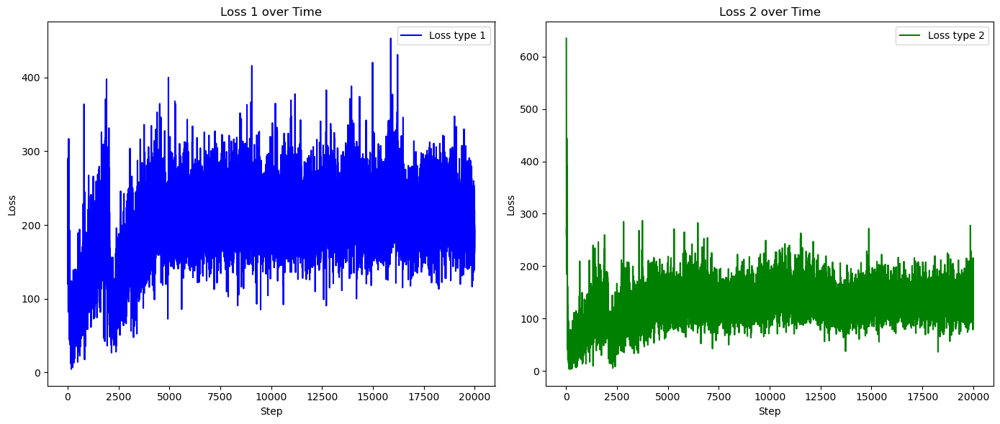

In [15]:
%matplotlib inline
plot_loss(type1_loss_lst, type2_loss_lst)

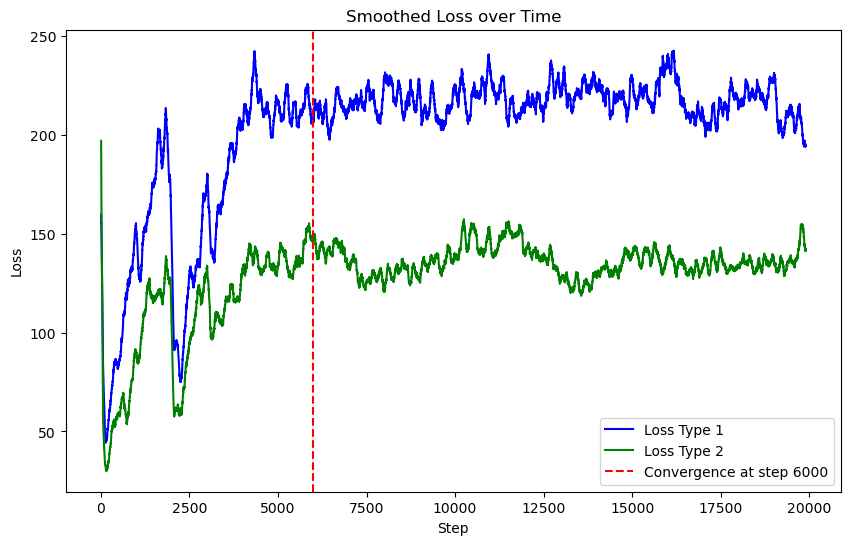

In [19]:
%matplotlib inline
plot_loss_curve(type1_loss_lst, type2_loss_lst)

In [74]:
# save train set and model
save_train_state_set_csv(train_set, "train_set.csv")

torch.save(agent, 'DQN.pth')

Train state set saved to train_set.csv.


In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Load the saved train set and model
train_set = load_train_state_set_csv("train_set.csv")
model  = torch.load('DQN.pth')
print(train_set)

Train state set loaded from train_set.csv.
{frozenset({"('type2', (((0, 4), 0), ((1, 0), 0)))", "('type1', (((3, 2), 0), ((0, 2), 0)))", "('b_position', (1, 3))"}), frozenset({"('type2', (((1, 1), 1), ((1, 2), 0)))", "('b_position', (3, 4))", "('type1', (((1, 1), 1), ((2, 2), 0)))"}), frozenset({"('type1', (((1, 1), 0), ((1, 2), 0)))", "('type2', (((0, 2), 0), ((3, 4), 0)))", "('b_position', (2, 3))"}), frozenset({"('type1', (((4, 3), 0), ((2, 1), 0)))", "('type2', (((0, 4), 0), ((0, 3), 0)))", "('b_position', (4, 0))"}), frozenset({"('type1', (((1, 2), 0), ((0, 0), 0)))", "('type2', (((0, 1), 0), ((0, 4), 0)))", "('b_position', (4, 3))"}), frozenset({"('type2', (((0, 2), 0), ((2, 1), 0)))", "('type1', (((3, 2), 0), ((3, 1), 0)))", "('b_position', (1, 4))"}), frozenset({"('type1', (((1, 4), 0), ((4, 4), 0)))", "('b_position', (0, 0))", "('type2', (((1, 0), 0), ((2, 2), 0)))"}), frozenset({"('type1', (((2, 0), 0), ((0, 0), 0)))", "('type2', (((0, 2), 0), ((4, 3), 0)))", "('b_position', 

/tmp/ipykernel_25266/522212539.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model  = torch.load('DQN.pth')


In [6]:
def validate(env, agent, episodes=100, train_set = None):
    '''Validate the DQN agent performance without exploration.
    Args:
        env: the environment to evaluate on.
        agent: the trained DQN agent.
        episodes: number of episodes to run for validation.
        render: if True, show the environment at each step (default false).
    Returns:
        success_rate: proportion of successful episodes.
        avg_reward: average reward across episodes.
    '''
    total_rewards = []
    step_error_list=[]
    aStar_distance_list=[]
    success_count = 0  # Count of successful episodes
    agent_types = ['type1', 'type2']
    actually_episodes = 0
    total_steps = []

    for episode in range(episodes):
        # initial environment for every episode
        state = env.reset()
        if train_set is not None:
            hashed_state = state.copy()
            # hashed for searching faster
            hashed_state['type1'] = tuple(hashed_state['type1'])
            hashed_state['type2'] = tuple(hashed_state['type2'])
            hashed_set = frozenset(hashed_state.items())
            if hashed_set in train_set:
                continue
        actually_episodes += 1    
        done = 0
        total_reward = 0
        steps = 0
        flag=True
        print(f'Episode {episode + 1}/{episodes}, initial state: {state}')

        while not done:
            for current_agent_type in agent_types:
                for current_agent_id in range(2):
                    # convert to a state vector
                    state_vector = agent.flatten_state(state, current_agent_type, current_agent_id)
                    
                    state_tensor = torch.tensor(state_vector, dtype=torch.float32).unsqueeze(0).to(device)
                    if current_agent_type == 'type1':
                        q_values = agent.type1_policy_net(state_tensor).detach().cpu().numpy()
                    else:
                        q_values = agent.type2_policy_net(state_tensor).detach().cpu().numpy()
                    action = np.argmax(q_values)
                    next_state, reward, done, _ = env.move(current_agent_type, current_agent_id, action)
                    total_reward += reward
                    
                    state = next_state # update state
                    
                    if done == 1:
                        break
                if done == 1:
                    success_count += 1
                    total_rewards.append(total_reward)
                    break
            steps += 1 # every 4 agent move once, we call it move one step
            # if the agent spend too many steps to finish its task, this episode should be fail, usually, agent should not spend exceed (4+4 + 4+4) steps to finish its task(for example, agent born on B, B is on right bottom, A is on left top. This is the worst case)
            if steps > 15:
                break
        total_steps.append(steps)
    
    avg_reward = np.mean(total_rewards)
    success_rate = success_count / actually_episodes
    avg_step = np.mean(total_steps)


    print(f"Validation Results - Actually episodes: {actually_episodes}, Success Rate: {success_rate*100:.2f}%, Avg Reward: {avg_reward:.2f}, Avg Step: {avg_step:.2f}")
    return success_rate, avg_reward, total_steps


In [81]:
# validation process
success_rate, avg_reward, total_steps = validate(env, model, episodes=50000, train_set=train_set)


Episode 1/50000, initial state: {'type1': [((0, 4), 0), ((2, 1), 0)], 'type2': [((1, 3), 0), ((3, 1), 0)], 'b_position': (2, 3)}
Episode 2/50000, initial state: {'type1': [((3, 0), 0), ((3, 4), 0)], 'type2': [((4, 3), 0), ((3, 3), 0)], 'b_position': (1, 0)}
Episode 3/50000, initial state: {'type1': [((0, 1), 0), ((0, 0), 0)], 'type2': [((4, 1), 0), ((2, 2), 0)], 'b_position': (2, 3)}
Episode 4/50000, initial state: {'type1': [((0, 2), 1), ((1, 2), 0)], 'type2': [((3, 4), 0), ((0, 2), 1)], 'b_position': (2, 2)}
Episode 5/50000, initial state: {'type1': [((0, 4), 0), ((4, 0), 0)], 'type2': [((4, 1), 0), ((0, 0), 0)], 'b_position': (3, 4)}
Episode 6/50000, initial state: {'type1': [((3, 4), 0), ((2, 4), 0)], 'type2': [((3, 3), 0), ((4, 4), 0)], 'b_position': (4, 3)}
Episode 7/50000, initial state: {'type1': [((3, 0), 0), ((1, 3), 1)], 'type2': [((1, 3), 1), ((2, 0), 0)], 'b_position': (3, 4)}
Episode 8/50000, initial state: {'type1': [((1, 3), 0), ((1, 2), 0)], 'type2': [((4, 2), 0), ((3,

In [10]:
# Switch to TkAgg backend
%matplotlib tk
plt.switch_backend('TkAgg')
import time

# Visualization using TkAgg
class GridVisualizer:
    def __init__(self, env, agent):
        '''Initialize the visualizer with environment and agent's policy network.
        Args:
            env: GridWorld environment.
            agent: Trained DQN agent.
        '''
        self.env = env
        self.agent = agent
        self.fig, self.ax = plt.subplots(figsize=(7, 7))
        self.visualize_grid()
        self.anim = FuncAnimation(self.fig, self.update, frames=self.generate_frames, repeat=False, save_count=100)

        plt.show()

    def visualize_grid(self):
        '''Set up the grid for visualization.'''
        self.ax.clear()
        self.ax.set_xlim(0, self.env.n)
        self.ax.set_ylim(self.env.n, 0)  # Invert the y-axis to place the origin at the top-left
        self.ax.set_xticks(np.arange(0, self.env.n + 1, 1))
        self.ax.set_yticks(np.arange(0, self.env.n + 1, 1))
        self.ax.xaxis.tick_top()
        self.ax.grid(True)

    def generate_frames(self):
        '''Generate frames for the animation by simulating the environment.'''
        # initial environment for every episode

        state = self.env.reset()
        done = 0
        total_reward = 0
        steps = 0
        flag=1
        agent_types = ['type1', 'type2']
        
        while not done:
            for current_agent_type in agent_types:
                for current_agent_id in range(2):
                    yield state
                    # convert to a state vector
                    state_vector = self.agent.flatten_state(state, current_agent_type, current_agent_id)
                    
                    state_tensor = torch.tensor(state_vector, dtype=torch.float32).unsqueeze(0).to(device)
                    
                                # Get the action from the trained DQN agent
                    with torch.no_grad():
                        if current_agent_type == 'type1':
                            q_values = self.agent.type1_policy_net(state_tensor).detach().cpu().numpy()
                        else:
                            q_values = self.agent.type2_policy_net(state_tensor).detach().cpu().numpy()
                    action = np.argmax(q_values)
                    next_state, reward, done, _ = env.move(current_agent_type, current_agent_id, action)
                    # total_reward += reward
                    # 
                    state = next_state # update state
                    # 
                    if done == 1:
                        break
                if done == 1:
                    break
            steps += 1 # every 4 agent move once, we call it move one step
            # if the agent spend too many steps to finish its task, this episode should be fail, usually, agent should not spend exceed (4+4 + 4+4) steps to finish its task(for example, agent born on B, B is on right bottom, A is on left top. This is the worst case)
            if steps > 30:
                break
        yield state
        
    def update(self, state):
        '''Update the plot for each frame.'''
        self.visualize_grid()
        # # Plot A position
        # self.ax.text(self.env.a_position[1] + 0.5, self.env.a_position[0] + 0.5, 'A', fontsize=12, ha='center',
        #              va='center', color='blue')
        # Plot B position
        self.ax.text(self.env.b_position[1] + 0.5, self.env.b_position[0] + 0.5, 'B', fontsize=12, ha='center',
                     va='center', color='blue')
        # Plot agent's position
        self.ax.text(self.env.get_all_state()['type1'][0][0][1] + 0.5, self.env.get_all_state()['type1'][0][0][0] + 0.5, 'Agent 10', fontsize=12,
                     ha='center', va='center', color='red' if env.get_all_state()['type1'][0][1] == 0 else 'green')
        
        self.ax.text(self.env.get_all_state()['type1'][1][0][1] + 0.5, self.env.get_all_state()['type1'][1][0][0] + 0.5, 'Agent 11', fontsize=12,
                     ha='center', va='center', color='red' if env.get_all_state()['type1'][1][1] == 0 else 'green')
        
        self.ax.text(self.env.get_all_state()['type2'][0][0][1] + 0.5, self.env.get_all_state()['type2'][0][0][0] + 0.5, 'Agent 20', fontsize=12,
                     ha='center', va='center', color='red' if env.get_all_state()['type2'][0][1] == 0 else 'green')
        
        self.ax.text(self.env.get_all_state()['type2'][1][0][1] + 0.5, self.env.get_all_state()['type2'][1][0][0] + 0.5, 'Agent 21', fontsize=12,
                     ha='center', va='center', color='red' if env.get_all_state()['type2'][1][1] == 0 else 'green')
        
        # time.sleep(1)

# Now, you can call the visualizer with the environment and trained agent
visualizer = GridVisualizer(env, model)


The shortest steps computation comes from minimax algorithm. Before enter B, agent with complete information must stay on the neighbour of B(North, South, East and West), then enter B. 

Therefore, firstly, for each neighbour, for each type of agent, we choose the minimal steps to the neighbor(min node).

Secondly, for each two different type agents(agent with complete information), we choose the max steps of the two different agents(max node).

Thirdly, for four neighbors, we choose the minimize steps(min node).


Pseudocode

Find neighbours of B position.

For neighbours in neighbours,
    Find minimize steps of current type
    Find the max step of the two types and add it to candidate shortest steps list

Find shortest steps among all the neighbours

step + 1 to enter B and finish the task



In [9]:
def manhattan(x, y):
    '''Return manhattan distance between x and y.
    Args:
        x: a tuple, coordination of position
        y: a tuple, coordination of position
    Returns:
        an integer of manhattan distance between x and y'''
    return abs(x[0] - y[0]) + abs(x[1] - y[1])

def shortest_steps(agent10_position, agent11_position, agent20_position, agent21_position, b_position):
    '''The question can simplify as a minmax algorithm, 4 agents went to nearest b, the first different type agent enter to its nearest
    (should have two different types here) is the shortest steps - 1
    Args:
        agent10_position: an tuple of agent 1 index 0 agent
        agent11_position: an tuple of agent 1 index 1 agent
        agent20_position: an tuple of agent 2 index 0 agent
        agent21_position: an tuple of agent 2 index 1 agent
    Returns:
        shortest_steps: an integer of shortest steps'''
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # North, South, East, West
    neighbors = []

    # add valid neighbours of b positions
    for d in directions:
        neighbor = (b_position[0] + d[0], b_position[1] + d[1])
        # Check if the neighbor is within grid boundaries
        if 0 <= neighbor[0] < 5 and 0 <= neighbor[1] < 5:
            neighbors.append(neighbor)

    shortest_steps = []
    for neighbor in neighbors:
        # min_part, type1 agent min distance to neighbor
        type1_min_distance = min(manhattan(agent10_position, neighbor), manhattan(agent11_position, neighbor))
        type2_min_distance = min(manhattan(agent20_position, neighbor), manhattan(agent21_position, neighbor))
        # max part, choose the max(second) distance as it step
        candidate_shortest_step = max(type1_min_distance, type2_min_distance)
        shortest_steps.append(candidate_shortest_step) # add this neighbor as candidate
    # min part, choose the shortest neighbor
    shortest_step = min(shortest_steps)
    # final step, one agent with complete info enter to b
    shortest_step += 1

    return shortest_step

In [10]:
def compare_with_minmax(env, agent, episodes=100, train_set = None, render = False, max_steps=15):
    '''Validate the DQN agent performance without exploration.
    Args:
        env: the environment to evaluate on.
        agent: the trained DQN agent.
        episodes: number of episodes to run for validation.
        train_set: hashed set of train set
        render: if True, show the environment at each step (default false).
        max_steps: maximum number of steps to run (default 15), if greater than the maximum number of steps, this episode will be marked as unsuccessful episode.
    Returns:
        success_rate: proportion of successful episodes.
        avg_reward: average reward across episodes.
        total_steps: a list, total number of steps at each episode. 
        optical_step_lst: optical steps list generate by minimax, in order to compare with the trained model
        step_error_lst: a list, comparing with optical_step_lst and find how many error step the agent have in an episode
        avg_error: average error across episodes.
    '''
    total_rewards = []
    step_error_lst=[]
    step_error_count_lst = []
    optical_step_lst = []
    success_count = 0  # Count of successful episodes
    agent_types = ['type1', 'type2']
    actually_episodes = 0
    total_steps = []

    for episode in range(episodes):
        # initial environment for every episode
        state = env.reset()
        if train_set is not None:
            hashed_state = state.copy()
            # hashed for searching faster
            hashed_state['type1'] = tuple(hashed_state['type1'])
            hashed_state['type2'] = tuple(hashed_state['type2'])
            hashed_set = frozenset(hashed_state.items())
            if hashed_set in train_set:
                continue
        agent10_position = state['type1'][0][0]
        agent11_position = state['type1'][1][0]
        agent20_position = state['type2'][0][0]
        agent21_position = state['type2'][1][0]
        b_position = state['b_position']
        actually_episodes += 1    
        done = 0
        total_reward = 0
        steps = 0
        if not render:
            print(f'Episode {episode + 1}/{episodes}, initial state: {state}')

        while not done:
            for current_agent_type in agent_types:
                for current_agent_id in range(2):
                    # convert to a state vector
                    state_vector = agent.flatten_state(state, current_agent_type, current_agent_id)
                    
                    state_tensor = torch.tensor(state_vector, dtype=torch.float32).unsqueeze(0).to(device)
                    if current_agent_type == 'type1':
                        q_values = agent.type1_policy_net(state_tensor).detach().cpu().numpy()
                    else:
                        q_values = agent.type2_policy_net(state_tensor).detach().cpu().numpy()
                    action = np.argmax(q_values)
                    next_state, reward, done, _ = env.move(current_agent_type, current_agent_id, action)
                    total_reward += reward
                    
                    state = next_state # update state
                    
                    if done == 1:
                        break
                if done == 1:
                    success_count += 1
                    total_rewards.append(total_reward)
                    break
            steps += 1 # every 4 agent move once, we call it move one step
            # if the agent spend too many steps to finish its task, this episode should be fail, usually, agent should not spend exceed (4+4 + 4+4) steps to finish its task(for example, agent born on B, B is on right bottom, A is on left top. This is the worst case)
            if steps > max_steps:
                break
        # add optical_step by minmax algorithm
        optical_step = shortest_steps(agent10_position, agent11_position, agent20_position, agent21_position, b_position)
        step_error = optical_step - steps
        # because I buy order update, there may be a condition that step error > 0, agent 10 start first and meet agent 20, then agent20 go to B. 
        # It should be 2 steps, but my algorithm will identify it as 1 step because of sequence update
        if step_error > 0:
            step_error = 0
            
        total_steps.append(steps)
        optical_step_lst.append(optical_step)
        # compare errors with current model and minmax algorithm, if not shortest path, we set error to true(1) else false(0, optical path)
        
        step_error_lst.append(step_error)
        step_error_count = 0 if abs(optical_step - steps) == 0 else 1
        step_error_count_lst.append(step_error_count)
        
        
    avg_error = sum(step_error_count_lst)/len(step_error_count_lst)
    avg_reward = np.mean(total_rewards)
    success_rate = success_count / actually_episodes
    avg_step = np.mean(total_steps)


    print(f"Validation Results - Actual Episodes: {actually_episodes}, "
          f"Success Rate: {success_rate*100:.2f}%, "
          f"Avg Reward: {avg_reward:.2f}, "
          f"Avg Step: {avg_step:.2f}, "
          f"Avg Error: {avg_error*100:.2f}%")
    return success_rate, avg_reward, total_steps, optical_step_lst, step_error_lst, avg_error


In [10]:

# compare with minimax
success_rate, avg_reward, total_steps, optical_step_lst, step_error_lst, avg_error = compare_with_minmax(env, model, episodes=50000, train_set=train_set, render=True)


Validation Results - Actual Episodes: 50000, Success Rate: 98.66%, Avg Reward: 137.43, Avg Step: 3.92, Avg Error: 47.11%


In [11]:
avg_excess_path_length = (-sum(step_error_lst))/len(step_error_lst)
print('avg_excess_path_length: ', avg_excess_path_length)

avg_excess_path_length:  0.69102


In [115]:
print(step_error_lst[-1000:])

[-1, 0, 0, -1, 0, 0, 0, 0, -2, 0, 0, 0, 0, 0, 0, -4, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, -2, -2, 0, 0, 0, 0, 0, 0, 0, 0, -28, 0, -3, 0, 0, 0, -1, -1, -2, 0, 0, 0, 0, 0, 0, 0, 0, -3, -2, -2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -2, 0, -1, -3, -1, 0, -2, 0, 0, -2, -2, -1, -1, 0, -2, 0, -2, 0, 0, 0, -1, -27, 0, 0, 0, -2, 0, -2, -2, 0, -1, 0, 0, 0, 0, 0, 0, 0, -2, 0, 0, -3, 0, 0, 0, -2, -2, 0, 0, 0, -2, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, -1, 0, 0, 0, -27, 0, -1, 0, -3, -1, 0, 0, 0, 0, 0, 0, 0, 0, -2, -2, 0, 0, -2, 0, 0, 0, 0, 0, -2, 0, 0, -1, -3, 0, 0, 0, 0, -1, -2, 0, 0, 0, 0, 0, -2, 0, -2, -1, -2, 0, 0, -1, 0, -1, 0, -1, 0, 0, 0, -1, 0, -1, 0, -1, 0, -27, 0, -1, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, -1, 0, 0, -2, 0, -2, 0, -1, 0, 0, -2, 0, 0, 0, 0, 0, -2, 0, 0, 0, 0, 0, 0, -1, 0, -2, 0, 0, -2, 0, 0, 0, -2, 0, -2, 0, 0, -2, 0, -2, 0, -1, 0, 0, -2, -2, -3, -1, 0, -1, 0, -1, 0, -2, -1, 0, 0, 0, 0, 

In [25]:
# Define device for computation
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize environment and DQN agent
n = 5  # Grid size
state_size = 7  # Agent type(1), agent id(1), agent position (2), b position(2) carrying item (1)

env = MultiAgentGridWorld(n)
agent = DQN_MultiAgent(n, state_size, learning_rate=5e-4, gamma=0.7)

# Train the DQN agent
dqn14_type1_loss_lst, dqn14_type2_loss_lst, dqn14_train_set = agent.train(env, episodes=19999, max_exploration=750)

Episode 1/19999, Total Reward: 97, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 2/19999, Total Reward: 83, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 3/19999, Total Reward: -82, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 4/19999, Total Reward: -628, Epsilon: 0.9, type1 loss: 285.0618896484375, type2 loss: 214.48526000976562
Episode 5/19999, Total Reward: 110, Epsilon: 0.9, type1 loss: 170.0701446533203, type2 loss: 143.6074981689453
Episode 6/19999, Total Reward: -315, Epsilon: 0.9, type1 loss: 162.21005249023438, type2 loss: 255.37274169921875
Episode 7/19999, Total Reward: -223, Epsilon: 0.9, type1 loss: 179.2386016845703, type2 loss: 295.34442138671875
Episode 8/19999, Total Reward: -629, Epsilon: 0.9, type1 loss: 265.9058532714844, type2 loss: 322.3904724121094
Episode 9/19999, Total Reward: -100, Epsilon: 0.9, type1 loss: 261.53521728515625, type2 loss: 310.1097717285156
Episode 10/19999, Total Reward: 16, Epsilon: 0.9, type1 loss: 292.18249511718

In [ ]:
save_train_state_set_csv(dqn14_train_set, "dqn14_train_set.csv")
torch.save(agent, 'DQN14.pth')

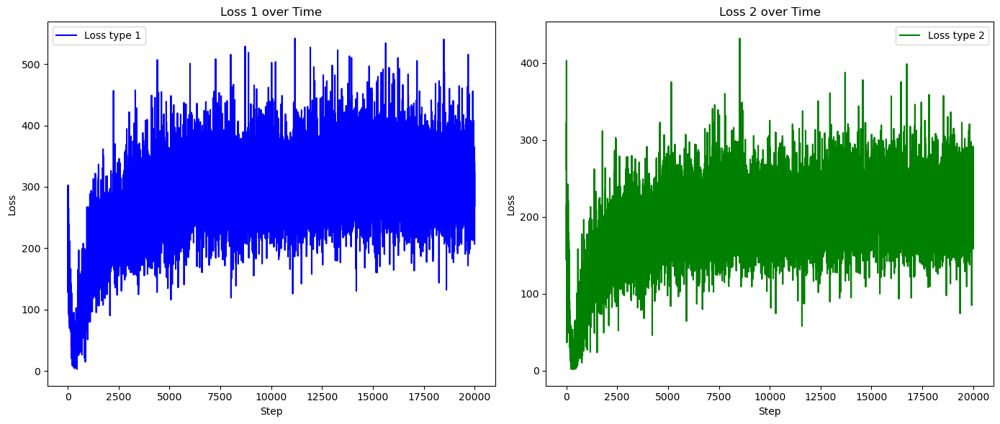

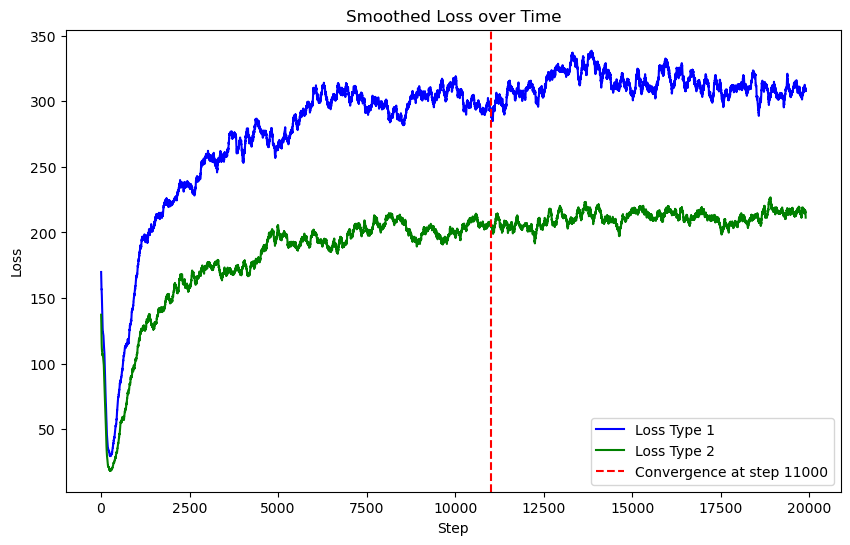

In [28]:
%matplotlib inline
plot_loss(dqn14_type1_loss_lst, dqn14_type2_loss_lst)
plot_loss_curve(dqn14_type1_loss_lst, dqn14_type2_loss_lst)

In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Load the saved train set and model
dqn14_train_set = load_train_state_set_csv("dqn14_train_set.csv")
model  = torch.load('DQN14.pth')
dqn14_success_rate, dqn14_avg_reward, dqn14_total_steps, dqn14_optical_step_lst, dqn14_step_error_lst, dqn14_avg_error = compare_with_minmax(env, model, episodes=50000, train_set=dqn14_train_set)


Train state set loaded from dqn14_train_set.csv.
Episode 1/50000, initial state: {'type1': [((3, 1), 0), ((0, 2), 0)], 'type2': [((2, 0), 0), ((2, 4), 0)], 'b_position': (4, 2)}
Episode 2/50000, initial state: {'type1': [((3, 4), 0), ((0, 3), 0)], 'type2': [((1, 1), 0), ((1, 3), 0)], 'b_position': (2, 0)}
Episode 3/50000, initial state: {'type1': [((1, 1), 0), ((3, 2), 0)], 'type2': [((0, 1), 0), ((1, 3), 0)], 'b_position': (2, 1)}
Episode 4/50000, initial state: {'type1': [((3, 3), 0), ((2, 1), 0)], 'type2': [((0, 3), 0), ((1, 1), 0)], 'b_position': (4, 3)}
Episode 5/50000, initial state: {'type1': [((2, 3), 0), ((3, 2), 0)], 'type2': [((0, 2), 0), ((3, 3), 0)], 'b_position': (0, 3)}
Episode 6/50000, initial state: {'type1': [((2, 2), 0), ((1, 3), 0)], 'type2': [((3, 0), 0), ((1, 4), 0)], 'b_position': (0, 2)}
Episode 7/50000, initial state: {'type1': [((0, 3), 0), ((1, 0), 0)], 'type2': [((3, 3), 0), ((4, 2), 0)], 'b_position': (3, 2)}
Episode 8/50000, initial state: {'type1': [((0, 

In [16]:
avg_excess_path_length = (-sum(dqn14_step_error_lst))/len(dqn14_step_error_lst)
print('avg_excess_path_length: ', avg_excess_path_length)

avg_excess_path_length:  0.37108


In [17]:
# Define device for computation
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize environment and DQN agent
n = 5  # Grid size
state_size = 7  # Agent type(1), agent id(1), agent position (2), b position(2) carrying item (1)

env = MultiAgentGridWorld(n)
agent = DQN_MultiAgent(n, state_size, learning_rate=5e-4, gamma=0.5)

# Train the DQN agent
dqn17_type1_loss_lst, dqn17_type2_loss_lst, dqn17_train_set = agent.train(env, episodes=19999, max_exploration=750)

Episode 1/19999, Total Reward: 135, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 2/19999, Total Reward: -499, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 3/19999, Total Reward: 102, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 4/19999, Total Reward: -5, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 5/19999, Total Reward: 149, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 6/19999, Total Reward: -38, Epsilon: 0.9, type1 loss: 242.23828125, type2 loss: 655.9400634765625
Episode 7/19999, Total Reward: -47, Epsilon: 0.9, type1 loss: 178.82447814941406, type2 loss: 467.9694519042969
Episode 8/19999, Total Reward: 142, Epsilon: 0.9, type1 loss: 154.19309997558594, type2 loss: 455.860107421875
Episode 9/19999, Total Reward: 31, Epsilon: 0.9, type1 loss: 209.7194366455078, type2 loss: 435.0619201660156
Episode 10/19999, Total Reward: -420, Epsilon: 0.9, type1 loss: 293.075927734375, type2 loss: 362.26220703125
Episode 11/19999, Total Reward: 1, E

In [ ]:
save_train_state_set_csv(dqn17_train_set, "dqn17_train_set.csv")
torch.save(agent, 'DQN17.pth')

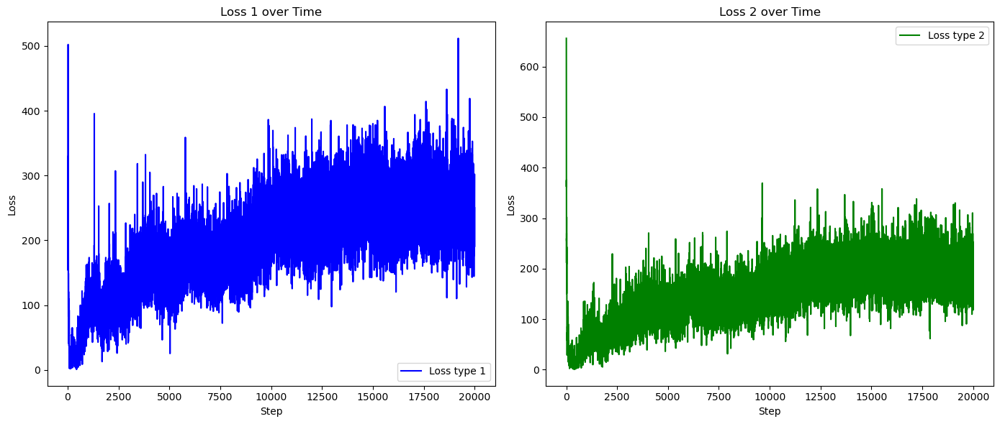

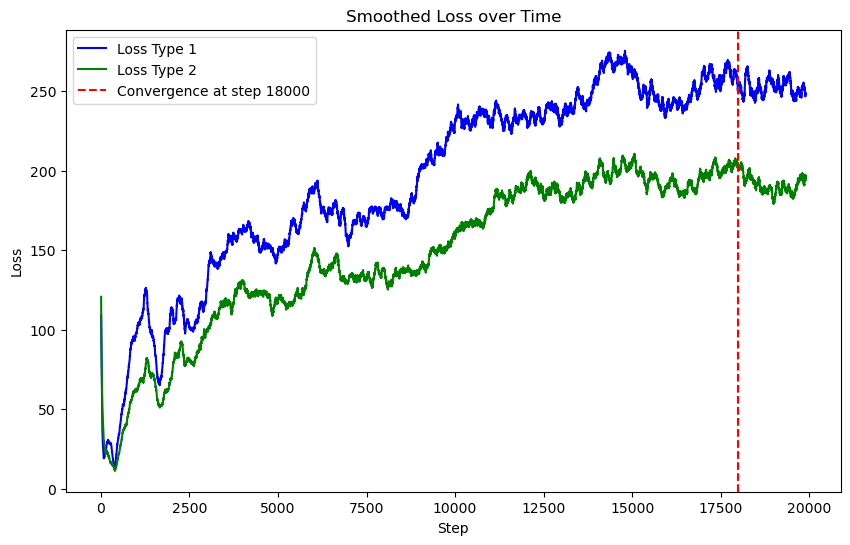

In [24]:
%matplotlib inline
plot_loss(dqn17_type1_loss_lst, dqn17_type2_loss_lst)
plot_loss_curve(dqn17_type1_loss_lst, dqn17_type2_loss_lst)

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Load the saved train set and model
dqn17_train_set = load_train_state_set_csv("dqn17_train_set.csv")
model  = torch.load('DQN17.pth')
dqn17_success_rate, dqn17_avg_reward, dqn17_total_steps, dqn17_optical_step_lst, dqn17_step_error_lst, dqn17_avg_error = compare_with_minmax(env, model, episodes=50000, train_set=dqn17_train_set)


Train state set loaded from dqn17_train_set.csv.
Episode 1/50000, initial state: {'type1': [((4, 0), 0), ((3, 4), 0)], 'type2': [((2, 2), 0), ((4, 4), 0)], 'b_position': (2, 0)}
Episode 2/50000, initial state: {'type1': [((3, 0), 1), ((1, 0), 0)], 'type2': [((3, 0), 1), ((1, 4), 0)], 'b_position': (3, 1)}
Episode 3/50000, initial state: {'type1': [((0, 2), 0), ((4, 3), 0)], 'type2': [((2, 3), 0), ((4, 2), 0)], 'b_position': (0, 0)}
Episode 4/50000, initial state: {'type1': [((3, 2), 0), ((4, 2), 0)], 'type2': [((4, 1), 0), ((2, 3), 0)], 'b_position': (2, 0)}
Episode 5/50000, initial state: {'type1': [((2, 3), 0), ((0, 4), 0)], 'type2': [((1, 1), 0), ((0, 2), 0)], 'b_position': (1, 2)}
Episode 6/50000, initial state: {'type1': [((1, 0), 0), ((3, 1), 0)], 'type2': [((1, 4), 0), ((1, 2), 0)], 'b_position': (4, 3)}
Episode 7/50000, initial state: {'type1': [((1, 3), 0), ((2, 4), 0)], 'type2': [((2, 2), 0), ((0, 1), 0)], 'b_position': (1, 0)}
Episode 8/50000, initial state: {'type1': [((3, 

In [17]:
avg_excess_path_length = (-sum(dqn17_step_error_lst))/len(dqn17_step_error_lst)
print('avg_excess_path_length: ', avg_excess_path_length)

avg_excess_path_length:  0.4218


In [124]:
# Define device for computation
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize environment and DQN agent
n = 5  # Grid size
state_size = 7  # Agent type(1), agent id(1), agent position (2), b position(2) carrying item (1)

env = MultiAgentGridWorld(n)
agent = DQN_MultiAgent(n, state_size, learning_rate=5e-4, gamma=0.3)

# Train the DQN agent
dqn18_type1_loss_lst, dqn18_type2_loss_lst, dqn18_train_set = agent.train(env, episodes=19999, max_exploration=750)

save_train_state_set_csv(dqn18_train_set, "dqn18_train_set.csv")
torch.save(agent, 'DQN18.pth')

Episode 1/19999, Total Reward: 11, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 2/19999, Total Reward: 88, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 3/19999, Total Reward: 67, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 4/19999, Total Reward: -211, Epsilon: 0.9, type1 loss: nan, type2 loss: nan
Episode 5/19999, Total Reward: 12, Epsilon: 0.9, type1 loss: 506.4587097167969, type2 loss: 218.42808532714844
Episode 6/19999, Total Reward: -202, Epsilon: 0.9, type1 loss: 495.0968933105469, type2 loss: 183.4822540283203
Episode 7/19999, Total Reward: 53, Epsilon: 0.9, type1 loss: 377.9818420410156, type2 loss: 166.9749755859375
Episode 8/19999, Total Reward: 126, Epsilon: 0.9, type1 loss: 269.4098815917969, type2 loss: 189.00534057617188
Episode 9/19999, Total Reward: -116, Epsilon: 0.9, type1 loss: 465.1496276855469, type2 loss: 202.27545166015625
Episode 10/19999, Total Reward: -7, Epsilon: 0.9, type1 loss: 451.46502685546875, type2 loss: 176.87425231933594

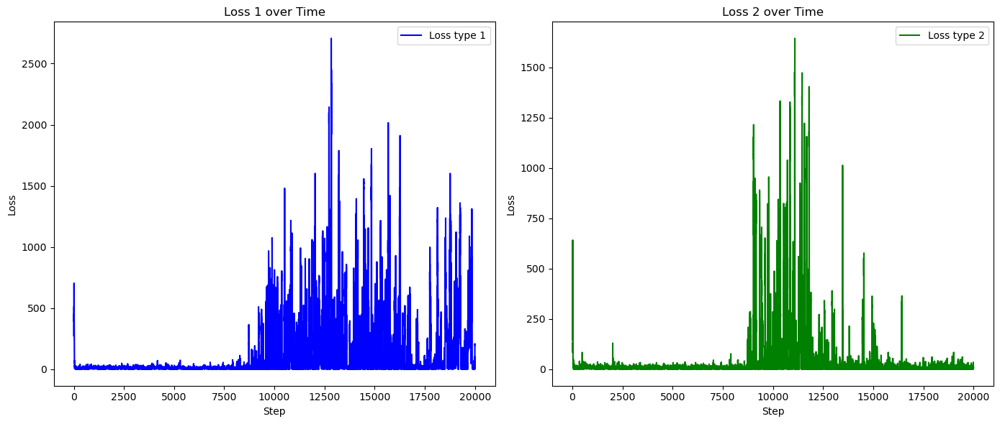

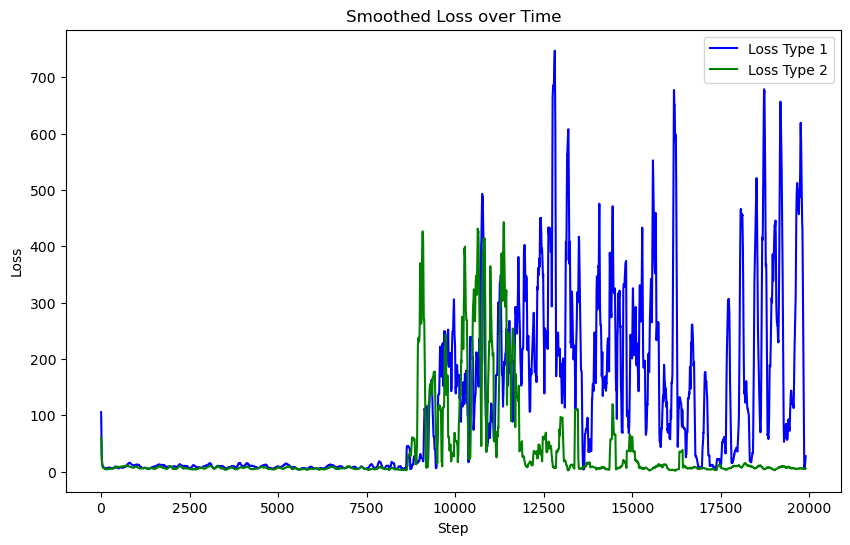

In [125]:
%matplotlib inline
plot_loss(dqn18_type1_loss_lst, dqn18_type2_loss_lst)
plot_loss_curve(dqn18_type1_loss_lst, dqn18_type2_loss_lst)

In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Load the saved train set and model
dqn18_train_set = load_train_state_set_csv("dqn18_train_set.csv")
model  = torch.load('DQN18.pth')
dqn18_success_rate, dqn18_avg_reward, dqn18_total_steps, dqn18_optical_step_lst, dqn18_step_error_lst, dqn18_avg_error = compare_with_minmax(env, model, episodes=50000, train_set=dqn18_train_set)


Train state set loaded from dqn18_train_set.csv.
Episode 1/50000, initial state: {'type1': [((2, 1), 0), ((3, 2), 0)], 'type2': [((1, 3), 0), ((4, 0), 0)], 'b_position': (2, 0)}
Episode 2/50000, initial state: {'type1': [((3, 0), 0), ((0, 4), 0)], 'type2': [((1, 3), 0), ((2, 2), 0)], 'b_position': (4, 0)}
Episode 3/50000, initial state: {'type1': [((3, 1), 0), ((3, 2), 0)], 'type2': [((2, 3), 0), ((1, 4), 0)], 'b_position': (0, 3)}
Episode 4/50000, initial state: {'type1': [((2, 3), 0), ((1, 4), 0)], 'type2': [((1, 1), 0), ((3, 0), 0)], 'b_position': (3, 2)}
Episode 5/50000, initial state: {'type1': [((0, 4), 0), ((4, 0), 0)], 'type2': [((2, 1), 0), ((3, 0), 0)], 'b_position': (1, 4)}
Episode 6/50000, initial state: {'type1': [((3, 2), 1), ((0, 2), 0)], 'type2': [((3, 2), 1), ((4, 1), 0)], 'b_position': (3, 4)}
Episode 7/50000, initial state: {'type1': [((4, 0), 0), ((0, 3), 0)], 'type2': [((2, 0), 0), ((3, 0), 0)], 'b_position': (3, 2)}
Episode 8/50000, initial state: {'type1': [((3, 

In [19]:
avg_excess_path_length = (-sum(dqn18_step_error_lst))/len(dqn18_step_error_lst)
print('avg_excess_path_length: ', avg_excess_path_length)

avg_excess_path_length:  6.4952


In [22]:
print(f'Model DQN success rate: , {success_rate*100: .4f}%, Model DQN avg error: , {avg_error*100: .4f}%, '
      f'Model DQN avg reward: , {avg_reward: .4f}, avg_steps: , {sum(total_steps) / len(total_steps): .4f}, avg_excess_path_length: {(-sum(step_error_lst))/len(step_error_lst): .4f}')

print(f'Model DQN14 success rate: , {dqn14_success_rate*100: .4f}%, Model DQN14 avg error: , {dqn14_avg_error*100: .4f}%, '
      f'Model DQN14 avg reward: , {dqn14_avg_reward: .4f}, dqn14_avg_steps: , {sum(dqn14_total_steps) / len(dqn14_total_steps): .4f}, dqn14_avg_excess_path_length: {(-sum(dqn14_step_error_lst))/len(dqn14_step_error_lst): .4f}')

print(f'Model DQN17 success rate: , {dqn17_success_rate*100: .4f}%, Model DQN17 avg error: , {dqn17_avg_error*100: .4f}%, '
      f'Model DQN14 avg reward: , {dqn17_avg_reward: .4f}, dqn17_avg_steps: , {sum(dqn17_total_steps) / len(dqn17_total_steps): .4f}, dqn17_avg_excess_path_length: {(-sum(dqn17_step_error_lst))/len(dqn17_step_error_lst): .4f}')

print(f'Model DQN18 success rate: , {dqn18_success_rate*100: .4f}%, Model DQN18 avg error: , {dqn18_avg_error*100: .4f}%, '
      f'Model DQN14 avg reward: , {dqn18_avg_reward: .4f}, dqn18_avg_steps: , {sum(dqn18_total_steps) / len(dqn18_total_steps): .4f}, dqn18_avg_excess_path_length: {(-sum(dqn18_step_error_lst))/len(dqn18_step_error_lst): .4f}')

Model DQN success rate: ,  98.6620%, Model DQN avg error: ,  47.1140%, Model DQN avg reward: ,  137.4262, avg_steps: ,  3.9247, avg_excess_path_length:  0.6910
Model DQN14 success rate: ,  99.7980%, Model DQN14 avg error: ,  40.3420%, Model DQN14 avg reward: ,  138.6978, dqn14_avg_steps: ,  3.5497, dqn14_avg_excess_path_length:  0.3711
Model DQN17 success rate: ,  99.2180%, Model DQN17 avg error: ,  39.7120%, Model DQN14 avg reward: ,  138.3922, dqn17_avg_steps: ,  3.6040, dqn17_avg_excess_path_length:  0.4218
Model DQN18 success rate: ,  53.4040%, Model DQN18 avg error: ,  78.5000%, Model DQN14 avg reward: ,  116.3111, dqn18_avg_steps: ,  9.7981, dqn18_avg_excess_path_length:  6.4952


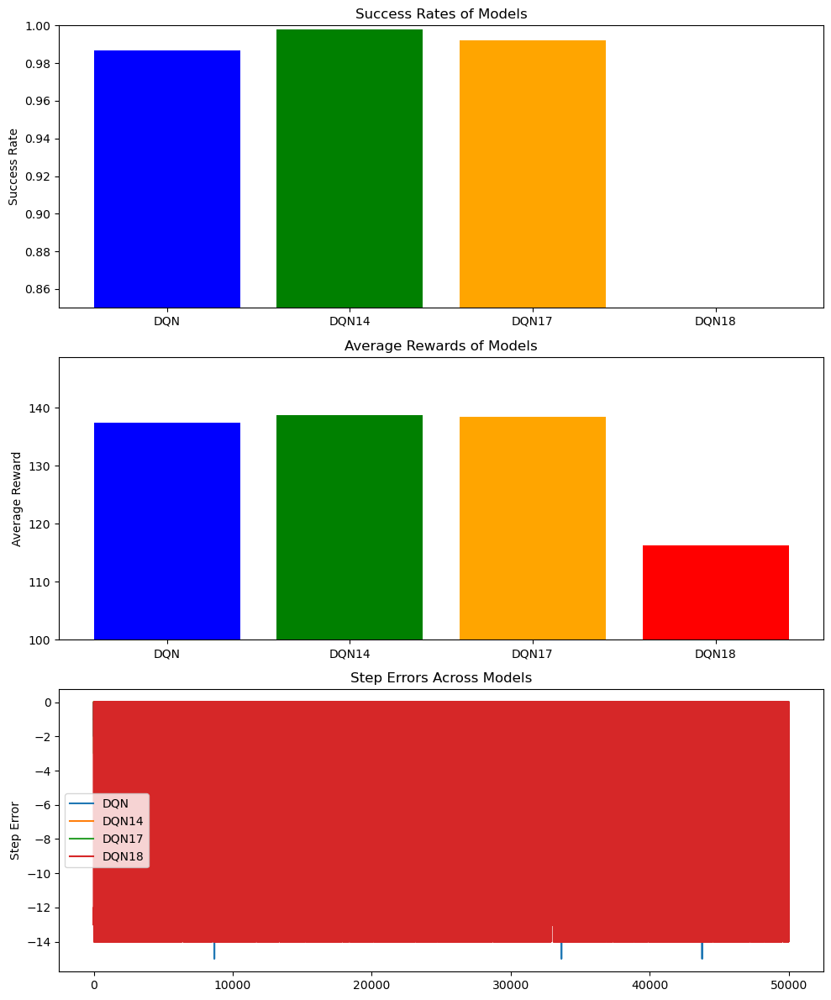

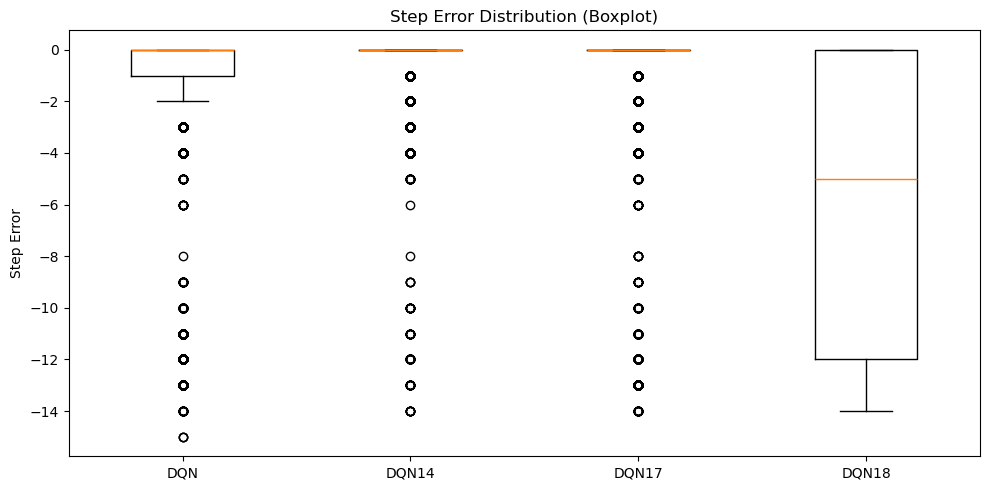

In [21]:
%matplotlib inline

def visualize_results(models, success_rates, avg_rewards, step_errors):
    """
    Visualize the success rates, average rewards, and step errors of four models.

    Parameters:
    models: list of model names
    success_rates: list of success rates
    avg_rewards: list of average rewards
    step_errors: list of step errors for each model
    """
    # Create the figure
    fig, ax = plt.subplots(3, 1, figsize=(10, 12))

    # Visualize Success Rates
    ax[0].bar(models, success_rates, color=['blue', 'green', 'orange', 'red'])
    ax[0].set_title('Success Rates of Models')
    ax[0].set_ylabel('Success Rate')
    ax[0].set_ylim([0.85, 1])  # Set y-axis range to display success rates

    # Visualize Average Rewards
    ax[1].bar(models, avg_rewards, color=['blue', 'green', 'orange', 'red'])
    ax[1].set_title('Average Rewards of Models')
    ax[1].set_ylabel('Average Reward')
    ax[1].set_ylim([100, max(avg_rewards) + 10])

    # Visualize Step Errors
    for i, errors in enumerate(step_errors):
        ax[2].plot(range(len(errors)), errors, label=models[i])
        ax[2].set_title('Step Errors Across Models')
        ax[2].set_ylabel('Step Error')
    ax[2].legend()

    # Display the plot
    plt.tight_layout()
    plt.show()

def visualize_step_error(models, step_errors):
    """
    Visualize the distribution and average of step errors.

    Parameters:
    models: list of model names
    step_errors: list of step errors for each model
    """
    # Calculate the standard deviation of step errors for each model
    std_errors = [np.std(errors) for errors in step_errors]

    # Create the figure
    fig, ax = plt.subplots(figsize=(10, 5))

    # Step Error Distribution - Using boxplot
    ax.boxplot(step_errors, labels=models)
    ax.set_title('Step Error Distribution (Boxplot)')
    ax.set_ylabel('Step Error')

    # Display the plot
    plt.tight_layout()
    plt.show()


# Assume you have already obtained data from the four models
def load_and_visualize():
    # Import data from models
    models = ['DQN', 'DQN14', 'DQN17', 'DQN18']

    # Put the results of the four models into lists
    success_rates = [success_rate, dqn14_success_rate, dqn17_success_rate, dqn18_success_rate]
    avg_rewards = [avg_reward, dqn14_avg_reward, dqn17_avg_reward, dqn18_avg_reward]
    step_errors = [step_error_lst, dqn14_step_error_lst, dqn17_step_error_lst, dqn18_step_error_lst]

    # Call the visualization functions
    visualize_results(models, success_rates, avg_rewards, step_errors)
    visualize_step_error(models, step_errors)


# Call the function to visualize
load_and_visualize()

| Model | Gamma | Alpha | Epsilon | Decay | Min  | train episodes | test episodes | test accuracy(%) | test reward | test average steps | test excess path length |
|-------|-------|-------|---------|-------|------|----------------|---------------|------------------|-------------|--------------------|-------------------------|
| DQN   | 0.9   | 0.8   | 0.9     | 0.99  | 0.01 | 19999          | 50000         | 98.6620          | 137.4262    | 3,9247             | 0.6910                  |
| DQN14 | 0.7   | 0.8   | 0.9     | 0.99  | 0.01 | 19999          | 50000         | 99.7980          | 138.6978    | 3.5497             | 0.3711                  |
| DQN17 | 0.5   | 0.8   | 0.9     | 0.99  | 0.01 | 19999          | 50000         | 99.2180          | 138.3922    | 3.6040             | 0.4218                  |
| DQN18 | 0.3   | 0.8   | 0.9     | 0.99  | 0.01 | 19999          | 50000         | 53.4040          | 116.3111    | 9.7981             | 6.4952                  |

# Documentation

I tested the above multiple sets of data, DQN is the data provided in the paper, but the effect is slightly worse, through the repeated tests, I found a more excellent value interval, the best model is 'DQN14'. And its best gamma value is 0.7, I got higher accuracy and less steps to finish the task.  

In this graph, the four different network models are shown on the x-axis, and the error with respect to the optimal solution is shown on the y-axis, where a negative error represents the gap with respect to the optimal solution. The horizontal line at the top represents the position of the optimal solution, and the outliers in the box represent the error values that have occurred. By labeling the outliers, this Boxplot can visualize the error between the models.

DQN14 has highest accuracy(99.7980%), lowest average steps(3.5497) and acceptable excess errors path length 0.3711. Therefore, we choose gamma = 0.7 as best parameter.

Additionally, For DQN14, I choose minimax algorithm as best performance(pseudocode refer shortest steps part). Success rate, average reward and abg error as metric to evaluate my model. 

how training test procedure and metrics work.

### why the agent will learn and What I expect my DQN to learn

Reason to use DQN, 

Before the assignment, I do a computation for the initial state(only consider all the agents in different positions), it is 25 * 24 * 23 * 22 * 21 = 6375600. And the initial state should actually greater than it because agent can born on anywhere except B position. I think it is hard to maintain such a huge q-table. Therefore, I choose the DQN and expand the layer for the huge initial state.

why the agents will learn,

I think it comes from the buffer, predict and target network(refer to slide 16 week 5). The buffer store the good experiences(it will delete the bad experience with time goes on). And the experience stored in buffer will feed to the predicted network to find the parameter to solve the task. With formular (reward + gamma*maxQ_target - Q_policy)**2, the loss can be computed. Only the two network get a similar parameters, the loss will become small. The backward will help us do this. However, we want the agent to finish the task. So we introduce the reward in target q value. The reward will encourage the agents to finish the task as soon as possible(full secret to B). However, for single agent, it is true to reduce the loss. But in this task, because agents cannot observe each other, loss is too small may lead the agent cannot finish the task successfully, so it may converge to a medium loss and finish the task. In conclusion, the agents can learn because buffer provide good experiences and the two network force the agents to find a mode to finish the task.

What I expect the DQN to learn,

I expect the agents to learn a mode(policy) that have high success rate to finish the task and cost less steps. In DQN14, I finished my tasks, with success rate 99.7980% and avg steps 3.5497 and average excess path length 0.3711, which mean every 100 episodes, only 0.2 episode will fail, the avg steps for each episode is 3.5497 steps and average excess 0.3711 steps. In conclusion, DQN14 satisfy what I expect my DQN to learn.

 
# training phase

When choosing DQN14 as best model, training 11000 episodes should be optical episodes.
 

# test procedure

I load my trained model and its corresponding training set. For each episode, choose initial state not in training set and using the trained model to complete the task and get the reward. After the model finished its task(it may not finish the task, if model not finish the task, the current episode will not be record as a success episode and the reward may be negative or very low, below 50), the minimax algorithm will also  compute the best steps and compared with model steps and compute the step error for each step. Finally, after all episodes are precessed, the algorithm will compute the success rate, average reward and avg error.

# metrics work:

I use success rate, average reward and avg error as metrics to evaluate my model.

success rate refers to how many times the model success in a given steps. For example, if the given step is 15, and the model finishes it task below 30 steps. We call it a success episode, vice versa. Finally, it will compute the success rate across all episodes. Generally, we need the success rate to be high, which means the model are stable to finish it task

average reward refers to average reward agent get across all episodes . Generally, we need the average reward to be high, which means the agent has higher probabilities to choose the best path to achieve its goal.

avg error mans compare with the best path, how many errors it made during  reaching the goal. In other words, it gives another idea on whether the model can find the best path to reach the goal. Generally,, we want the avg error to be low, which means the agent can always find its best path.




# Conclusion
 1. DQN 14 is a good model for this task. I test my model 50000 episodes with DQN 14. And the success rate is 99.87%, average reward for each episode is 138.64 and average error with 40.27. Which means my model is stable(success rate 99.87%) to finish the task with short steps(average reward 138.64). However, it is always hard to find the optical path(40.27% error). Although it has high errors on find the optical path, the high reward also indicate it still find a good path. It may only cost extra 1 or 2 steps to finish the task, which still indicate a good model.
2. I observed that at loss part, the loss firstly very high, then decrease very fast, later it will increase and finally converges at a high loss(around 250). I think firstly it is very high because the initial DQN is not trained, agents explores much and have a high loss. Then it decrease fast because it finds some policies like a single agent network. However, this is a multiple agents network, when exploration much, they may easily meet and finished the tasks. When both network finds its best policies independent. They also need to share secrets to finish the task(increase the loss to make they path not 'optical' to finish the task, just like a process of finding a mix strategy in a game). And finally they will converge to a range of values(seems both of them find the mix strategy). If consider the process as game with rational players. Firstly agents exploration a lot and they have high probability meeting, so the loss from very high to low. However, it is not a fair strategy for them when they choose not exploration so much. Therefore, both of them will find a mix or fair strategy to finish the task. This is why the loss increase, finally, they find a fair strategy and at this time, the loss converges. But it is not optical path, so the loss still large. 
3. I observed the type 1 loss is  always large than type 2 loss. I think the difference come from my codes. I buy the central clock. Therefore, type 1 agent always start first then type 2. This means at exchange secrete part, type 1 will always start first. It can be seen as type 1 always explore more than type 2(spend more time to find type 2 rather than directly choose the best path). This will harm the network, so the loss higher than type 2. If there is no special sequence for type 1 and type 2. I believe the difference of loss will not be so large.  
4. I think in my DQN, both the loss and reward are punished its network. Agents want to finish the task to get the reward. However, loss will push the agents to go to B. Both of them will punish the agents(reward -1, loss value), reward also give reward for a success episode. Under this condition, agents will find a balanced(Equilibrium) strategy to satisfy both of them.
5. Gamma determine the agent prefer to have high success rate or low loss. When gamma is great, agents prefer to have high success rate. However, when gamma is low, agents prefer to have low loss. I think the difference is because gamma determines how strongly each state links to the next state. In fact, we can use week5 slide 16 easily explain why loss become small, but success rate become low. loss = (reward + gamma*max_q_target - q_policy)**2, when gamma is small, agents focus more on immediate reward. We have many -1 reward in buffer, so the agents will prefer to go to the -1 grid(not finish the task), and those experience will be bad experience add to buffer. It will finally make the agent to go to those -1 grid rather than to finish the task and get high reward.   

# Game Theoretic Analysis

# Nash Equilibrium

To simplify the scenario, firstly we will simplify the model and do some assumptions. Then we will expand to to a complex scenario

## Assumptions

1. Agents will always try to find the nearby B as meeting point(later I will explain why agents choose this strategy) and they will immediately meeting if they choose meeting first(M) strategy.
2. We only consider two different types agents in analysis(two agents are absolute the same with a same type, just extract two different types agent for analysing)
3. We firstly do not consider step punish, which means -1 is not consider. We only consider the meeting reward(50), go to B with secrets(100), go to B without secrets(-100) to simplify the task.(Later this assumption will be discussed)
4. One agent finished its task will not terminate the task, the other agent can still go to B and get reward. But the agent without full secret will still get -100 reward, they will not get positive reward if they meet at B(to solve the sequence issue for payoff matrix, it is important in my code, but here I simplify the task for a high level analyse).
5. If agent use meeting first strategy. It will always find the different type of agent without full secret first. 


## model the question(players, strategy, payoff)

1. Two different types of players, type1 called agent 1, type2 called agent 2
2. Two strategies, both agents have strategy 1) meeting first(M, get reward 50 only for agent who choose this strategy) and go to B(100) 2) go to B without meeting(-100)
3. Payoff. 1) use first meeting(M) strategy agent will get reward(50) 2)go to be with full secret will get reward 100 3)go to B with out full secret get reward -100 

Base on those items, setting the payoff matrix


|                       | Type2: Go to B (G) | Type2: Meet First (M) |
|-----------------------|--------------------|-----------------------|
| Type1: Go to B (G)    | (-100, -100)       | (-100, +150)          |
| Type1: Meet First (M) | (+150, -100)        | (+150, +150)          |


explanation,

1. (1, 1), both agents choose to go to B without exchange secrets. Under this condition, they will both get reward -100;
2. (1, 2), agent 1 choose to meeting first and then go to B, agent 2 choose go to B directly. Agent 1 get 50 for Meeting and 100 for finish task. Agent get -100(assumption 5 ensure agent 2 now do not have full secret);
3. (2, 1), same with (1, 2);
4. (2, 2), both agents choose meeting first and then go to B(get reward 150, assumption 5 ensure both agents can get reward, not first one go to B).


## Analyse the outcomes of the game,

From the table, when type 1 choose G, if type 2 choose G, it will find M is better than choose G, so type 2 will switch to M; When type 2 switch to M, type 1 finds choose M will get higher utility, it will switch to M, finally type 1 and type 2 will all switch to (+150, +150). Same, when type 2 choose G, when type 1 choose G, it will find M is better, it will switch to M; When type 1 switch to M, type 2 will also find switch to M is better. Finally, type 1 and type to will all switch to (+150, +150).     

In conclusion, whatever the agents choose strategy, it will final switch to the (+150, +150). Therefore, the (+150, +150) is Pareto Optimality and it is also Pure Nash Equilibrium. Compare to our experiment, we can found that when gamma is high(the agent cares future), agents will finally converge to policy which has high success rate finish its task. It is the same with our game theory expected.

## Argument, agents’ behaviour can be expected to converge on a fair solution 

From previous analyse, we found a Pure Nash in this game, so the agents' behaviour should converge solution, which means all agents will try to meet first and then go to B. To be more specific, Agents will first go to nearby B(explained at explain assumption 1 below) to meet first and go to B. My DQN14 demonstrate the argument, with increased episodes, agents will tend to meet first and then deliver to B. The loss first very large then decrease then increase and converge to a range demonstrate the agents' choose their behaviours.

## Discuss the comparative merits of analysing the expected behaviour experimentally using the Q-learning implementation or theoretically using game theory 
 
### Merits of Theoretical Game-Theory Analysis:

Simplicity: Game theory provides a clear and straightforward analysis of strategic interactions between agents without requiring complex simulations and computation resources. It quickly identifies equilibrium points and helps predict how rational agents should behave.

Insight into Optimal Behavior: Game theory can highlight optimal strategies (like meeting first) and show how these are superior to alternative strategies (like going to B directly).

Generalization: The theoretical model can be also apply to other model, like prisoner dilemma.

### Merits of Experimental Q-learning Analysis:

Dynamic Learning: Q-learning experiments show how agents learn over time. They may initially make suboptimal choices (e.g., going to B directly) but gradually converge to better strategies (e.g., meeting first).

Specific and detailed: Q-learning is more specific, the different behaviour can be visualize and students can easily find the stable strategy agents will choose. Detailed, the more detailed information(for example, loss value type 1 greater than type 2) can be observed on Q-learning, which indicate the sequence of agents will also have influence on agent strategy. It cannot be observed in game theory that the order of the sequence can slight change the policy.

Exploration and Exploitation: Q-learning captures the exploration-exploitation tradeoff in a way game theory does not. Agents may sometimes explore suboptimal paths before discovering the best strategies. For example, my DQN14 40% time find the suboptimal path. It cannot be presented on game theory.

 ## Are there any aspects that only one of these analyses can cover?
Game Theory: It simplifies the problem, focusing on strategy selection and payoffs but ignores learning processes and exploration.
 
Q-learning: It captures the actual learning process, showing how agents discover optimal strategies over time, but it can be computationally expensive. And it only satisfy the grid 5*5, cannot be generalise to another scenario.

# More aspects about this question(Another Nash)


## explain assumption 1, why agents always try to find nearby B as meeting point

Firstly, model the question with a case and agents are rational. Because assignments assumes the distance the two agents have to travel from their start position to the meeting point. We can model one case like below:


| AGENT 1     |             |             |             | B POSITION |
|-------------|-------------|-------------|-------------|------------|
|             |             |             | CANDIDATE 4 |            |
|             |             | CANDIDATE 3 |             |            |
|             | CANDIDATE 2 |             |             |            |
| CANDIDATE 1 |             |             |             | AGENT 2    |

We model agent 1 at (0, 0), agent 2 at (4, 4), B position (0, 4), candidate 1 (4, 0), candidate 2 (3, 1), candidate3 (2, 2), candidate 3 (1, 3). If agents 

choose candidate 1 as meeting point, it get reward after finish the task, 150 - 12 = 138,  

choose candidate 2 as meeting point, 150 - 10 = 140,

choose candidate 3 as meeting point, 150 - 8 = 142,

choose candidate 4 as meeting point, 150 - 6 = 144,

Convert to below,

| AGENT 1  |           |          |          | B POSITION |
|----------|-----------|----------|----------|------------|
|          |           |          | 144, 144 |            |
|          |           | 142, 142 |          |            |
|          | 140, 140  |          |          |            |
| 138, 138 |           |          |          | AGENT 2    |

From the table, we can also find a Pure Nash, (144, 144). Therefore, agents meeting point will always choose the nearby B point. Compare to the experiment with validate, we can observe that agents always meet at nearby B. It is true with our observation on experiment.

# Population game
We can model as a population game and find what strategy the agents will choose

## model the game
1. we remain the agents with type1 and type2(Initial same numbers), however, now we assume the number of agents will be unlimited.
2. the payoff matrix same with Nash part, 

|                       | Type2: Go to B (G)                | Type2: Meet First (M)            | proportion                         | 
|-----------------------|-----------------------------------|----------------------------------|------------------------------------|
| Type1: Go to B (G)    | (-100, -100)                      | (-100, +150)                     | p1 (proportion of type1  choose G) |
| Type1: Meet First (M) | (+150, -100)                      | (+150, +150)                     | 1- p1 (1 - p1 of type1 choose M)   | 
|                       | p2(proportion of type1  choose G) | 1 - p2(1 - p2 of type2 choose M) |                                    | 

3. The game will not end when one agent finish the task, and every agent finishes the task will get reward 100(with complete secret) or -100(without complete secret)
4. When a agent enter B, it will not move again.


## strategies
for type1, p1 of them will choose go to G, (1 - p1) of them will choose M. We initial p1 = 0.5(half agents choose G, half choose M)

for type2, p2 of them will choose go to G, (1 - p2) of them will choose M. We initial p2 = 0.5(half agents choose G, half choose M)

## payoff
For type 1, the payoff depend on how many type2 also choose M

choose strategy M, payoff_1_M = 150 * p2 + 150 * (1 - p2)

choose strategy G, payoff_1_G = -100 * p2 + -100 * (1 - p2)  

average payoff avg_payoff_1 = p1 * payoff_1_M + (1 - p1)*payoff_1_G


same for type 2,

choose strategy M, payoff_2_M = 150 * p1 + 150 * (1 - p1)

choose strategy G, payoff_2_G = -100 * p1 + -100*(1 - p1)  

average payoff avg_payoff_2 = p2 * payoff_2_M + (1 - p2)*payoff_2_G

## replicator dynamic 

for type 1, pr1 = p1*(payoff_1_M - avg_payoff_1)

for type 2, pr2 = p2*(payoff_2_M - avg_payoff_2)

if pr1 > 0 or pr2 > 0, which means more agents will choose strategy M

use codes to show results


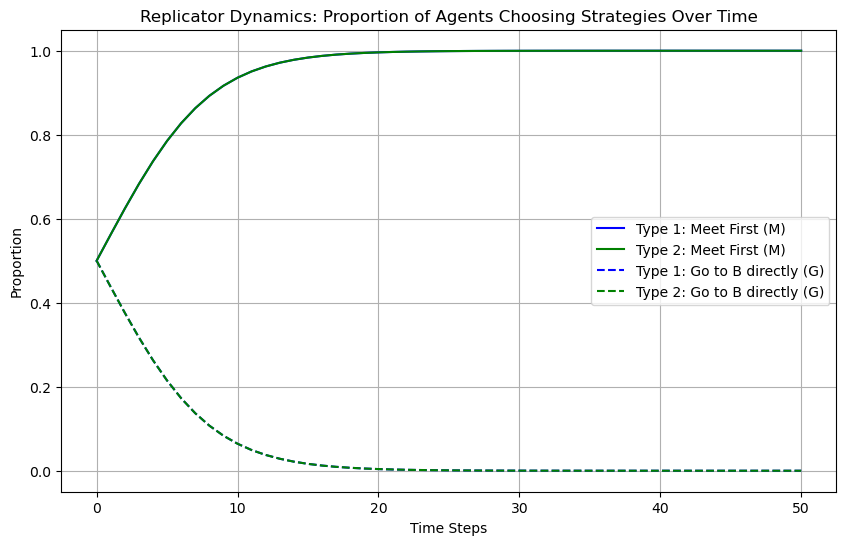

In [3]:

%matplotlib inline

# Replicator dynamics for a simple two-strategy population game

def replicator_dynamics(p1_init, p2_init, timesteps, delta_t):
    """
    Simulates the replicator dynamics for the two populations, Type 1 and Type 2.
    
    Args:
    - p1_init: Initial proportion of Type 1 agents choosing Meet First (M).
    - p2_init: Initial proportion of Type 2 agents choosing Meet First (M).
    - timesteps: Number of time steps to simulate.
    - delta_t: Step size for the simulation.
    
    Returns:
    - p1_history: Array of proportions of Type 1 agents choosing Meet First over time.
    - p2_history: Array of proportions of Type 2 agents choosing Meet First over time.
    """
    
    # Initialize proportions for Type 1 and Type 2 agents
    p1 = p1_init
    p2 = p2_init
    
    p1_history = [p1]
    p2_history = [p2]

    for t in range(timesteps):
        # Payoffs for Type 1 and Type 2 agents
        payoff_M1 = 150 * p2 + 150 * (1 - p2)
        payoff_G1 = -100 * p2 + (-100) * (1 - p2)
        
        payoff_M2 = 150 * p1 + 150 * (1 - p1)
        payoff_G2 = -100 * p1 + (-100) * (1 - p1)
        
        # Average payoffs for Type 1 and Type 2 agents
        avg_payoff_1 = p1 * payoff_M1 + (1 - p1) * payoff_G1
        avg_payoff_2 = p2 * payoff_M2 + (1 - p2) * payoff_G2
        
        # Replicator dynamic equations
        dp1_dt = p1 * (payoff_M1 - avg_payoff_1)
        dp2_dt = p2 * (payoff_M2 - avg_payoff_2)
        
        # Update the proportions using Euler's method
        p1 += delta_t * dp1_dt
        p2 += delta_t * dp2_dt
        
        # Ensure that proportions stay within [0, 1]
        p1 = np.clip(p1, 0, 1)
        p2 = np.clip(p2, 0, 1)
        
        p1_history.append(p1)
        p2_history.append(p2)
    
    return np.array(p1_history), np.array(p2_history)

# Simulation parameters
p1_init = 0.5  # Initial proportion of Type 1 agents choosing Meet First (M)
p2_init = 0.5  # Initial proportion of Type 2 agents choosing Meet First (M)
timesteps = 50  # Number of time steps to simulate
delta_t = 0.001  # Time step size

# Run the simulation
p1_history, p2_history = replicator_dynamics(p1_init, p2_init, timesteps, delta_t)

# Modify the plotting to also show the proportion of agents choosing "Go to B directly (G)"
def plot_replicator_dynamics(p1_history, p2_history):
    """
    Plot the replicator dynamics showing the proportion of agents choosing both "Meet First" and "Go to B directly".
    
    Args:
    - p1_history: Array of proportions of Type 1 agents choosing Meet First over time.
    - p2_history: Array of proportions of Type 2 agents choosing Meet First over time.
    """
    
    # Calculate proportions choosing "Go to B directly (G)" as (1 - p1) and (1 - p2)
    p1_G_history = 1 - p1_history
    p2_G_history = 1 - p2_history
    
    # Create the plot
    plt.figure(figsize=(10, 6))
    
    # Plot proportions choosing "Meet First"
    plt.plot(p1_history, label="Type 1: Meet First (M)", color='blue')
    plt.plot(p2_history, label="Type 2: Meet First (M)", color='green')
    
    # Plot proportions choosing "Go to B directly"
    plt.plot(p1_G_history, label="Type 1: Go to B directly (G)", linestyle='--', color='blue')
    plt.plot(p2_G_history, label="Type 2: Go to B directly (G)", linestyle='--', color='green')
    
    plt.xlabel("Time Steps")
    plt.ylabel("Proportion")
    plt.title("Replicator Dynamics: Proportion of Agents Choosing Strategies Over Time")
    plt.legend()
    plt.grid(True)
    plt.show()

# Plot both strategies
plot_replicator_dynamics(p1_history, p2_history)



## conclusion
From the visualization, type 1 and type 2 are prefer to meeting first with time goes on. In fact, it is true with our experiment, when gamma is large, which means agents have to consider more on future reward, in other words, consider more on get the max reward(finish the task). The training will finally converge to a high success rate model. Population game give us another insight on agents prefer  to meeting first or directly go to B with low computation resource consume. However, it is not specific to see if agent focus more on immediate reward, what should we do. 

# Coalitional Games

The game can also model as a coalition games to find whether it is a fair game

## model the question
1. we marked type1 agents with 10, 11; type2 agents with 20, 21
2. two different types agents meeting and enter B will get reward 150, agents without meeting different type agents and enter B will get reward -100
3. N = {10, 11, 20, 21}
4. v(empty) = 0
5. v({10})=v({11})=v({20})=v({21}) = -100
6. v({10, 11})=v({20, 21}) = -100
7. v({10, 20})=v({10, 21})=v({11, 20})=v({11, 21}) = 150
8. v({10, 11, 20})=v({10,11,21})=v({10,20,21})=v({10,11,20}) = 150
9. v({10, 11, 20, 21}) = 150

## Inference(shapley value)
Thus we can treat it as a simple game, refer to week 10 slide 31, permutation below

### Shapley Value Calculation Table

| Permutation    | 10   | 11   | 20   | 21   |
|----------------|------|------|------|------|
| 10,11,20,21    | -100 | 0    | 250  | 0    |
| 10,11,21,20    | -100 | 0    | 250  | 0    |
| 10,20,11,21    | -100 | 0    | 250  | 0    |
| 10,20,21,11    | -100 | 0    | 250  | 0    |
| 10,21,11,20    | -100 | 0    | 0    | 250  |
| 10,21,20,11    | -100 | 0    | 0    | 250  |
| 11,10,20,21    | 0    | -100 | 0    | 250  |
| 11,10,21,20    | 0    | -100 | 0    | 250  |
| 11,20,10,21    | 0    | -100 | 0    | 250  |
| 11,20,21,10    | 0    | -100 | 0    | 250  |
| 11,21,10,20    | 0    | -100 | 0    | 250  |
| 11,21,20,10    | 0    | -100 | 0    | 250  |
| 20,10,11,21    | 250  | 0    | -100 | 0    |
| 20,10,21,11    | 250  | 0    | -100 | 0    |
| 20,11,10,21    | 250  | 0    | -100 | 0    |
| 20,11,21,10    | 250  | 0    | -100 | 0    |
| 20,21,10,11    | 250  | 0    | 0    | -100 |
| 20,21,11,10    | 250  | 0    | 0    | -100 |
| 21,10,11,20    | 0    | 250  | 0    | -100 |
| 21,10,20,11    | 0    | 250  | 0    | -100 |
| 21,11,10,20    | 0    | 250  | 0    | -100 |
| 21,11,20,10    | 0    | 250  | 0    | -100 |
| 21,20,10,11    | 0    | 250  | -100 | -100 |
| 21,20,11,10    | 0    | 250  | -100 | -100 |

### Totals

- **Sum for 10**: 900
- **Sum for 11**: 900
- **Sum for 20**: 900
- **Sum for 21**: 900

### Shapley Values

- **Shapley value for 10**: 37.5
- **Shapley value for 11**: 37.5
- **Shapley value for 20**: 37.5
- **Shapley value for 21**: 37.5

In order to be fair, each member should get reward 37.5, they are all same, so it's a fair game

### Inference(core)
convert model question 

5. v({10})=v({11})=v({20})=v({21}) = -100
6. v({10, 11})=v({20, 21}) = -100
7. v({10, 20})=v({10, 21})=v({11, 20})=v({11, 21}) = 150
8. v({10, 11, 20})=v({10,11,21})=v({10,20,21})=v({10,11,20}) = 150
9. v({10, 11, 20, 21}) = 150

to 

5. v({10})=v({11})=v({20})=v({21}) = 0
6. v({10, 11})=v({20, 21}) = 0
7. v({10, 20})=v({10, 21})=v({11, 20})=v({11, 21}) = 1
8. v({10, 11, 20})=v({10,11,21})=v({10,20,21})=v({10,11,20}) = 1
9. v({10, 11, 20, 21}) = 1

we get

### Condition Table

| Set            | Condition |
|----------------|-----------|
| {10}           | x >= 0    |
| {11}           | x >= 0    |
| {20}           | x >= 0    |
| {21}           | x >= 0    |
| {10,11}        | x >= 0    |
| {20,21}        | x >= 0    |
| {10,20}        | x >= 1    |
| {10,21}        | x >= 1    |
| {11,20}        | x >= 1    |
| {11,21}        | x >= 1    |
| {10,20,21}     | x >= 1    |
| {10,11,20}     | x >= 1    |
| {10,11,21}     | x >= 1    |
| {10,11,20,21}  | x >= 1    |

## conclusion
From the table, there is no veto player. From Theorem: In a simple game the core is empty iff there is no veto player(week 10 slide 41). We can draw a conclusion that the core is empty.

In conclusion, this is a fair game and there is no veto player in this game. In other words, the game is stable and no agents will have an incentive to deviate from the coalition. Compare to our experiment, single agent cannot finish its task without complete secret. It is true with our experiment.
